# GPSA Analysis - WT vs T419R

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from io import StringIO


## Delta Energy Terms

### Load data

In [4]:
def load_finalenergy (mut):
    dfs = []
    for rep in range(1, 4):
        energyfile = (f'../../data/1bf5/{mut}/rep{rep}/analysis/006_gbsa/FINAL_ENERGY.csv')
        with open(energyfile, 'r') as f:
            lines = f.readlines()

        # Find the index of the line containing "Delta Energy Terms"
        start_idx = None
        for i, line in enumerate(lines):
            if "Delta Energy Terms" in line:
                start_idx = i + 1  # Start from the next line
                break

        if start_idx is None:
            raise ValueError("Section 'Delta Energy Terms' not found in the file")

        # Extract the lines after "Delta Energy Terms"
        data_lines = lines[start_idx:]
        data_string = ''.join(data_lines)
        df = pd.read_csv(StringIO(data_string))
        dfs.append(df)
    return dfs


In [5]:
wt_delta_dfs = load_finalenergy('wt')
T419R_delta_dfs = load_finalenergy('T419R')

In [6]:
wt_delta_dfs[0].head()

,Frame #,BOND,ANGLE,DIHED,VDWAALS,EEL,1-4 VDW,1-4 EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
0,1000,0.0,0.0,0.0,-133.98,-277.39,0.0,0.0,260.99,-18.82,-411.37,242.17,-169.21
1,1001,0.0,0.0,0.0,-137.18,-297.28,-0.0,-0.0,281.92,-18.93,-434.46,262.98,-171.48
2,1002,-0.0,-0.0,-0.0,-135.61,-299.07,-0.0,0.0,282.32,-20.45,-434.68,261.87,-172.81
3,1003,0.0,0.0,0.0,-134.28,-298.42,0.0,0.0,283.22,-19.71,-432.69,263.52,-169.18
4,1004,-0.0,-0.0,0.0,-131.69,-282.88,-0.0,0.0,266.81,-19.98,-414.57,246.83,-167.74


Columns: 
- BOND: Bond stretching energy
- ANGLE: Angle bending energy
- DIHED: Dihedral (torsional) energy
- VDWAALS: van der Waals energy
- EEL: Electrostatic energy
- 1-4 VDW: 1-4 van der Waals energy
- 1-4 EEL: 1-4 Electrostatic energy
- EGB: Generalized Born energy
- ESURF: Surface (non-polar solvation) energy
- GGAS: Gas-phase energy. (BOND + ANGLE + DIHED + VDWAALS + EEL + 1-4 VDW + 1-4 EEL)
- GSOLV: Solvation energy. (EGB + ESURF)
- TOTAL: Total energy. (GGAS + GSOLV)

### By replicate

Plot delta energy terms by replicate.

In [7]:
wt_delta_dfs[0].describe()

,Frame #,BOND,ANGLE,DIHED,VDWAALS,EEL,1-4 VDW,1-4 EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
count,1002.000000,1002.0,1002.0,1002.0,1002.000000,1002.000000,1002.0,1002.0,1002.000000,1002.000000,1002.000000,1002.000000,1002.000000
mean,1500.500000,0.0,0.0,0.0,-147.208054,-321.256806,0.0,0.0,304.558393,-19.942605,-468.464551,284.615729,-183.848743
std,289.396786,0.0,0.0,0.0,9.438355,25.177154,0.0,0.0,23.818368,0.911887,27.355557,23.564614,9.822645
min,1000.000000,-0.0,0.0,0.0,-176.550000,-398.030000,0.0,-0.0,242.260000,-22.610000,-551.770000,222.510000,-217.090000
25%,1250.250000,0.0,0.0,0.0,-154.020000,-337.855000,0.0,0.0,288.500000,-20.540000,-486.032500,268.350000,-190.877500
50%,1500.500000,0.0,0.0,0.0,-147.720000,-318.480000,0.0,0.0,302.130000,-19.970000,-466.715000,282.260000,-184.310000
75%,1750.750000,0.0,-0.0,0.0,-140.545000,-304.205000,0.0,0.0,320.137500,-19.330000,-450.807500,299.782500,-176.625000
max,2001.000000,-0.0,0.0,0.0,-120.250000,-253.990000,0.0,-0.0,378.590000,-17.110000,-391.460000,358.500000,-156.460000


In [8]:
wt_delta_summary = []

for df in wt_delta_dfs:
    desc = df.describe()
    desc = desc.filter(items = ['mean', 'std'], axis=0)
    desc.loc['sem'] = df.sem()
    desc = desc.drop(['Frame #', 'BOND', 'ANGLE', 'DIHED', '1-4 VDW', '1-4 EEL'], axis=1)
    wt_delta_summary.append(desc)

T419R_delta_summary = []

for df in T419R_delta_dfs:
    desc = df.describe()
    desc = desc.filter(items = ['mean', 'std'], axis=0)
    desc.loc['sem'] = df.sem()
    desc = desc.drop(['Frame #', 'BOND', 'ANGLE', 'DIHED', '1-4 VDW', '1-4 EEL'], axis=1)
    T419R_delta_summary.append(desc)

In [9]:
wt_delta_summary[0]

,VDWAALS,EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
mean,-147.208054,-321.256806,304.558393,-19.942605,-468.464551,284.615729,-183.848743
std,9.438355,25.177154,23.818368,0.911887,27.355557,23.564614,9.822645
sem,0.298169,0.795377,0.752451,0.028808,0.864195,0.744434,0.310309


In [10]:
T419R_delta_summary[0]

,VDWAALS,EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
mean,-131.113084,-395.252854,375.156088,-17.808623,-526.366038,357.347415,-169.018503
std,10.393187,26.096295,24.419629,0.899971,26.456242,24.316758,10.072246
sem,0.328333,0.824413,0.771445,0.028431,0.835784,0.768196,0.318194


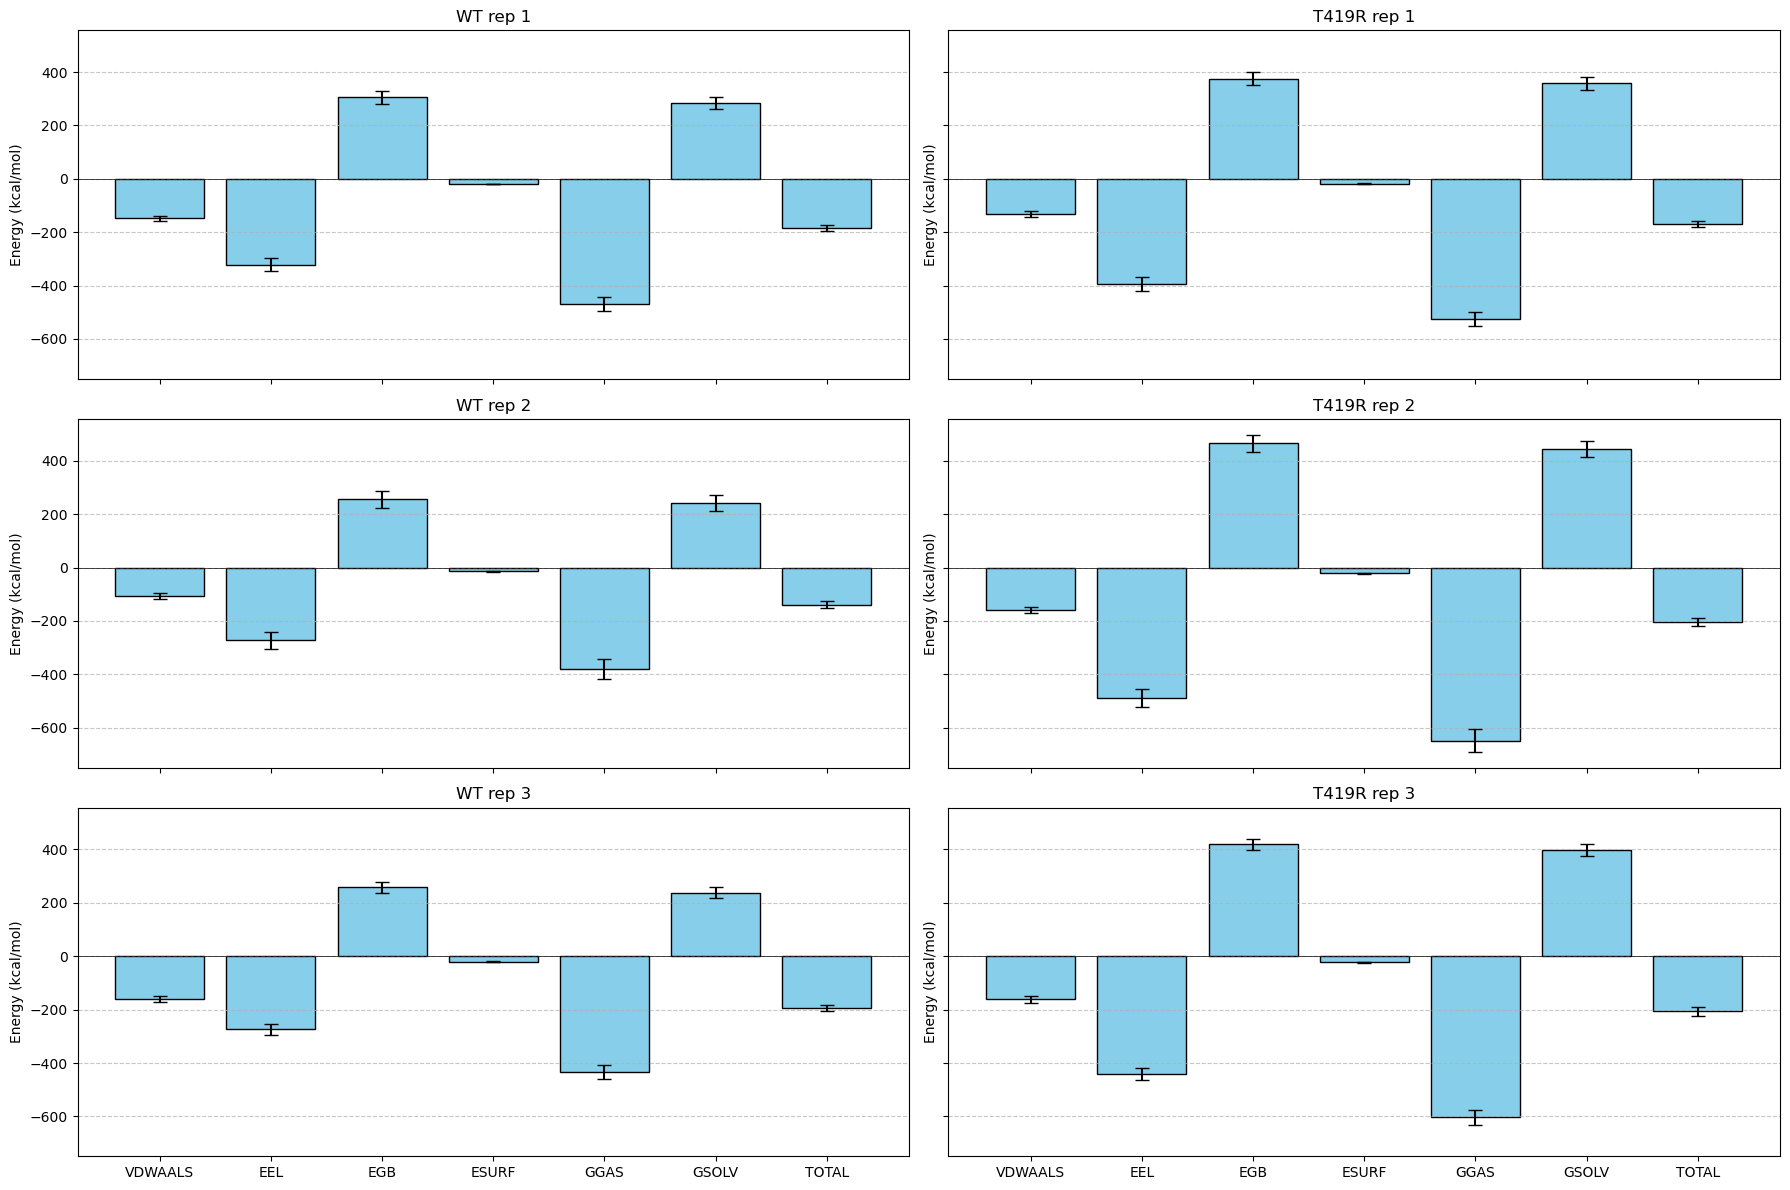

In [11]:

# Find global min and max
all_data = [
    wt_delta_summary[0].transpose().values,
    wt_delta_summary[1].transpose().values,
    wt_delta_summary[2].transpose().values,
    T419R_delta_summary[0].transpose().values,
    T419R_delta_summary[1].transpose().values,
    T419R_delta_summary[2].transpose().values
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(3, 2, figsize=(18, 12), sharey=True, sharex=True)
ax1, ax2, ax3, ax4, ax5, ax6 = axes.flatten()

plots = [
    (wt_delta_summary[0].transpose(), ax1, 'WT rep 1'),
    (T419R_delta_summary[0].transpose(), ax2, 'T419R rep 1'),
    (wt_delta_summary[1].transpose(), ax3, 'WT rep 2'),
    (T419R_delta_summary[1].transpose(), ax4, 'T419R rep 2'),
    (wt_delta_summary[2].transpose(), ax5, 'WT rep 3'),
    (T419R_delta_summary[2].transpose(), ax6, 'T419R rep 3'),
]

for df, ax, title in plots:
    ax.bar(df.index, df['mean'], yerr=df['std'], capsize=5, color='skyblue', edgecolor='black')
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)


plt.tight_layout()
plt.show()

#### Interpretation

At first glance, the total energy delta is very similar between WT and T419R, around -200 kcal/mol. The second WT replicate has the most outlying total value. However, this similarity in the total energy might be due to the components of the calculation balancing each other out. T419R has higher absolute values for EEL, GGAS, EGB and GSOLV. As the first two have negative values and the last two have positive values, the differences might be cancelling each other, resulting in a total value similar to the WT.

GGAS is lower is because it includes EEL, which is lower, indicating stronger electrostatic interactions between STAT1 T419R and DNA. Similarly, the increase in GSOLV is mainly a result of the increase in EGB, reflecting reduced polar solvation. In other words, the charged groups solvate less favorably in water, compared to the WT. This might reflect some of this residues being more deeply buried in the binding interface, as seen in the 3D structures, where the positive ARG is attracted to the negative DNA backbone and inserted between its bases.

### By mutation (combining replicates)

In [12]:
def combine_delta(dfs):
    combined_means = []
    combined_stds = []

    # Combine for each energy term
    for col in dfs[0].columns:
        means = [df.loc['mean', col] for df in dfs]
        stds = [df.loc['std', col] for df in dfs]
        
        # Simple mean 
        combined_mean = np.mean(means)
        
        # Pooled variance and combined std
        variances = [s**2 for s in stds]
        pooled_variance = np.mean(variances)  # Since n_frames is the same, (n-1) terms cancel out
        combined_std = np.sqrt(pooled_variance)
        
        combined_means.append(combined_mean)
        combined_stds.append(combined_std)

    combined_df = pd.DataFrame({
        col: [combined_means[i], combined_stds[i]] for i, col in enumerate(wt_delta_summary[0].columns)
    }, index=['mean', 'std'])
    return combined_df


In [13]:
wt_combined_df = combine_delta(wt_delta_summary)
T419R_combined_df = combine_delta(T419R_delta_summary)

In [14]:
wt_combined_df 

,VDWAALS,EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
mean,-137.768796,-289.567532,273.126104,-18.365023,-427.336244,254.760951,-172.575176
std,9.984252,27.278466,25.747698,1.298792,30.623010,25.194886,11.030096


In [15]:
T419R_combined_df

,VDWAALS,EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
mean,-150.892325,-441.685795,419.739182,-20.224188,-592.578177,399.514867,-193.063117
std,12.571365,27.823674,26.355668,1.487646,32.843131,25.861099,13.792357


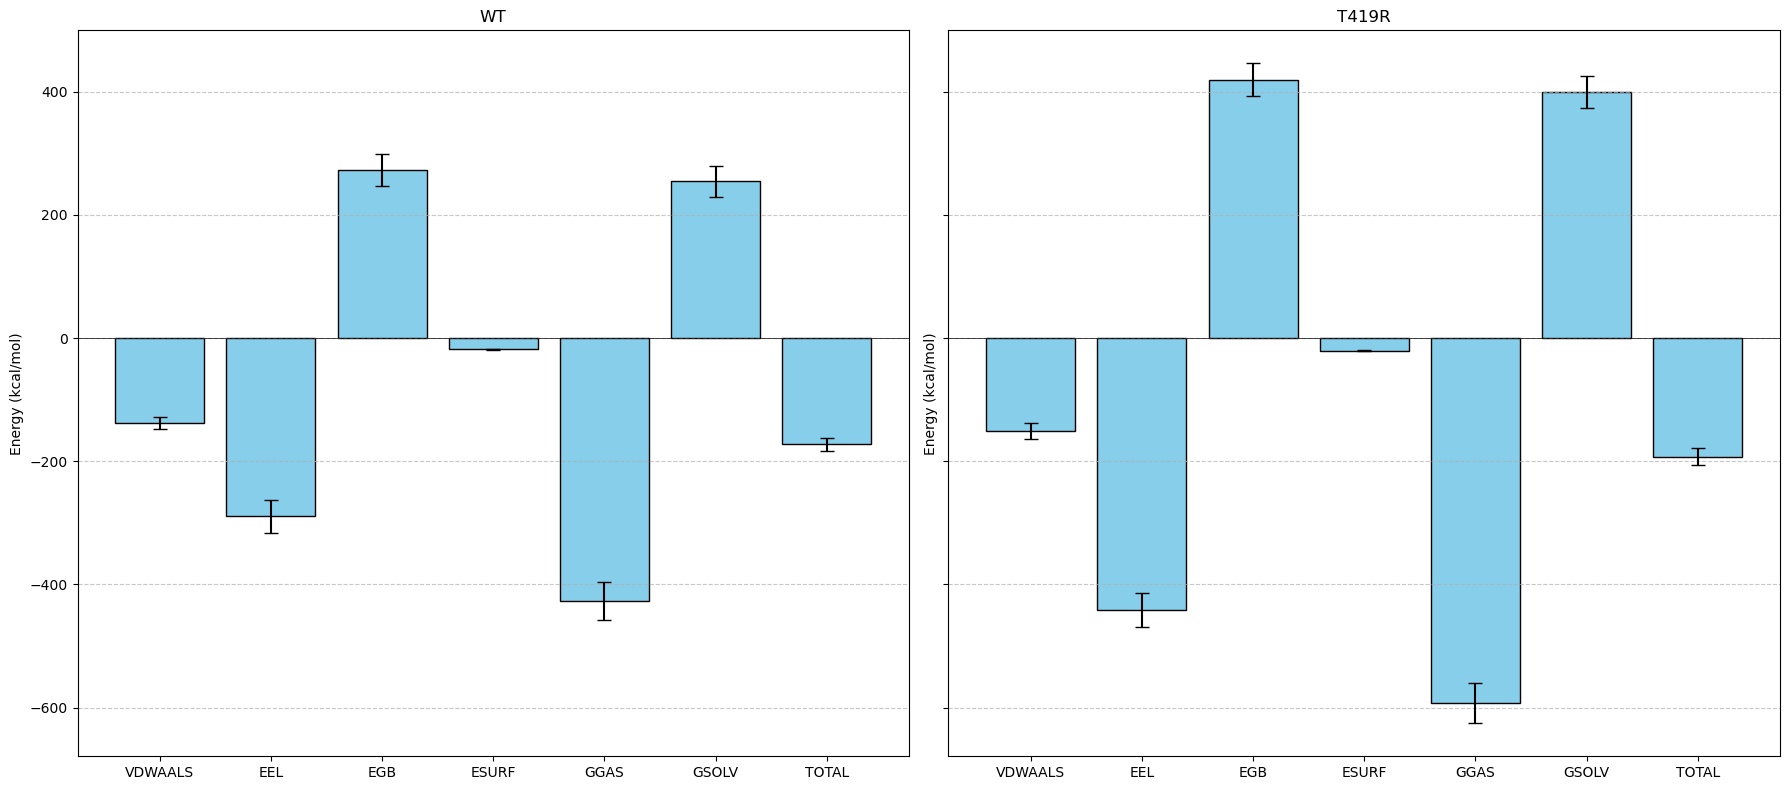

In [16]:

# Find global min and max
all_data = [
    wt_combined_df.transpose().values,
    T419R_combined_df.transpose().values,
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(1, 2, figsize=(18, 8), sharey=True, sharex=True)
ax1, ax2 = axes.flatten()

plots = [
    (wt_combined_df.transpose(), ax1, 'WT'),
    (T419R_combined_df.transpose(), ax2, 'T419R'),
]

for df, ax, title in plots:
    ax.bar(df.index, df['mean'], yerr=df['std'], capsize=5, color='skyblue', edgecolor='black')
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)


plt.tight_layout()
plt.show()

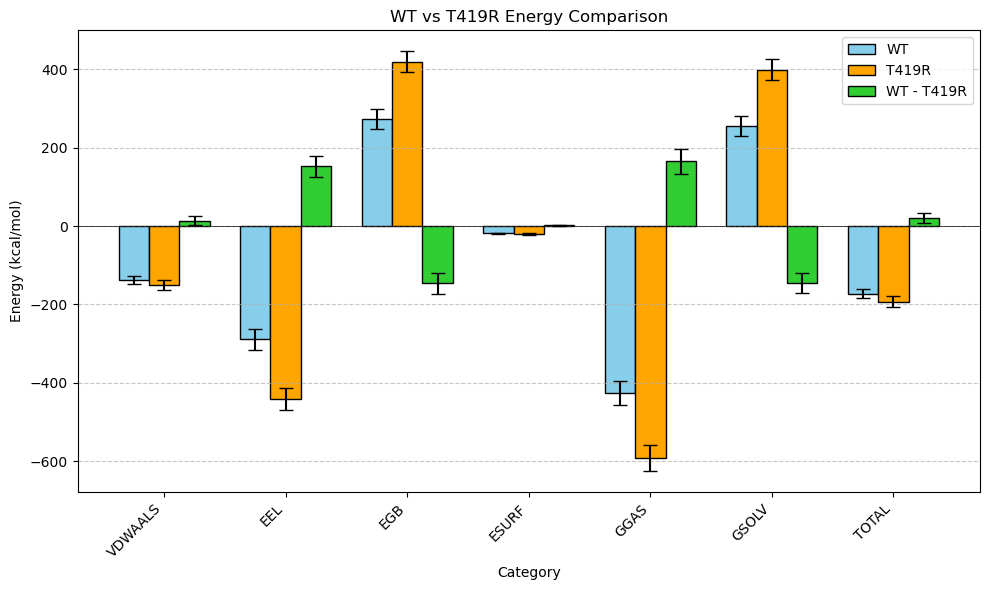

In [47]:
wt_combined_df_t = wt_combined_df.transpose()
T419R_combined_df_t = T419R_combined_df.transpose()

# Find global min and max 
all_data = [
    wt_combined_df_t.values,
    T419R_combined_df_t.values,
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

# Verify that dfs have the same index
if not wt_combined_df_t.index.equals(T419R_combined_df_t.index):
    raise ValueError("Indices of wt_combined_df_t and T419R_combined_df_t do not match!")


diff_df = pd.DataFrame({
    'mean': wt_combined_df_t['mean'] - T419R_combined_df_t['mean'],
    'std': np.sqrt((wt_combined_df_t['std']**2 + T419R_combined_df_t['std']**2) / 2)  # Pooled standard deviation
}, index=wt_combined_df_t.index)

fig, ax = plt.subplots(figsize=(10, 6))

labels = wt_combined_df_t.index  
x = np.arange(len(labels))  # Positions for bar groups
width = 0.25

# Plot WT bars
ax.bar(x - width, wt_combined_df_t['mean'], width, yerr=wt_combined_df_t['std'], 
       capsize=5, color='skyblue', edgecolor='black', label='WT')

# Plot T419R bars
ax.bar(x, T419R_combined_df_t['mean'], width, yerr=T419R_combined_df_t['std'], 
       capsize=5, color='orange', edgecolor='black', label='T419R')

# Plot difference (WT - T419R) bars
ax.bar(x + width, diff_df['mean'], width, yerr=diff_df['std'], 
       capsize=5, color='limegreen', edgecolor='black', label='WT - T419R')

ax.set_title('WT vs T419R Energy Comparison')
ax.set_xlabel('Category')
ax.set_ylabel('Energy (kcal/mol)')
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=45, ha='right')
ax.grid(True, axis='y', linestyle='--', alpha=0.7)
ax.axhline(0, color='black', linewidth=0.5)
ax.legend()

plt.tight_layout()
plt.show()

In [48]:
table_df = pd.DataFrame({
    'Category': wt_combined_df_t.index,
    'WT Mean (kcal/mol)': wt_combined_df_t['mean'].round(2),
    'WT Std (kcal/mol)': wt_combined_df_t['std'].round(2),
    'T419R Mean (kcal/mol)': T419R_combined_df_t['mean'].round(2),
    'T419R Std (kcal/mol)': T419R_combined_df_t['std'].round(2),
    'Difference Mean (kcal/mol)': diff_df['mean'].round(2),
    'Difference Std (kcal/mol)': diff_df['std'].round(2)
})

# Generate LaTeX table rows
latex_rows = []
for _, row in table_df.iterrows():
    latex_rows.append(
        f"{row['Category']} & {row['WT Mean (kcal/mol)']} & {row['WT Std (kcal/mol)']} & "
        f"{row['T419R Mean (kcal/mol)']} & {row['T419R Std (kcal/mol)']} & "
        f"{row['Difference Mean (kcal/mol)']} & {row['Difference Std (kcal/mol)']} \\\\"
    )

# Print LaTeX table rows to copy into Overleaf
print("\n".join(latex_rows))
table_df

VDWAALS & -137.77 & 9.98 & -150.89 & 12.57 & 13.12 & 11.35 \\
EEL & -289.57 & 27.28 & -441.69 & 27.82 & 152.12 & 27.55 \\
EGB & 273.13 & 25.75 & 419.74 & 26.36 & -146.61 & 26.05 \\
ESURF & -18.37 & 1.3 & -20.22 & 1.49 & 1.86 & 1.4 \\
GGAS & -427.34 & 30.62 & -592.58 & 32.84 & 165.24 & 31.75 \\
GSOLV & 254.76 & 25.19 & 399.51 & 25.86 & -144.75 & 25.53 \\
TOTAL & -172.58 & 11.03 & -193.06 & 13.79 & 20.49 & 12.49 \\


,Category,WT Mean (kcal/mol),WT Std (kcal/mol),T419R Mean (kcal/mol),T419R Std (kcal/mol),Difference Mean (kcal/mol),Difference Std (kcal/mol)
VDWAALS,VDWAALS,-137.77,9.98,-150.89,12.57,13.12,11.35
EEL,EEL,-289.57,27.28,-441.69,27.82,152.12,27.55
EGB,EGB,273.13,25.75,419.74,26.36,-146.61,26.05
ESURF,ESURF,-18.37,1.30,-20.22,1.49,1.86,1.40
GGAS,GGAS,-427.34,30.62,-592.58,32.84,165.24,31.75
GSOLV,GSOLV,254.76,25.19,399.51,25.86,-144.75,25.53
TOTAL,TOTAL,-172.58,11.03,-193.06,13.79,20.49,12.49


#### Interpretation

The aggregated values reinforce the hypothesis formulated from the results of the separate replicates. The total energy value of T419R is only slighly lower than of WT, indicating slightly stronger binding. Interestingly, the energy decomposition points at the nature of this difference. 

The electrostatic energy (EEL) of T419R is lower, with a mean of -441.69 ± 27.82 kcal/mol, compared to the wild-type (WT) mean of -289.57 ± 27.28 kcal/mol, indicating stronger electrostatic interactions in the mutant. Conversely, the higher generalized Born energy (EGB) of mean 419.74 ± 26.36 kcal/mol of T419R, compared to 273.13 ± 25.75 kcal/mol in WT, indicate the polar solvation of the mutant has been reduced, possibly due to the mutated residues being buried in the binding interface. In short, the aggregated data points towards a tighter binding of mutant T419R to DNA, albeit with a small effect in total energy.

## Residue decomposition

### Load data

In [18]:
def load_decompenergy(mut):
    dfs = []
    for rep in range(1, 4):
        energyfile = f'../../data/1bf5/{mut}/rep{rep}/analysis/006_gbsa/FINAL_ENERGY_DECOMP.csv'
        with open(energyfile, 'r') as f:
            lines = f.readlines()

        # Find the start and end indices for the section
        start_idx = None
        end_idx = None
        for i, line in enumerate(lines):
            line_clean = line.strip()
            if "DELTAS:" in line_clean:
                start_idx = i + 2  # Skip "DELTAS:" and "Total Decomposition Contribution (TDC)"
                continue
            if start_idx is not None and "Sidechain Decomposition Contribution" in line_clean:
                end_idx = i  
                break

        # Extract the lines between start_idx and end_idx
        data_lines = lines[start_idx:end_idx]
        data_string = ''.join(data_lines)

        df = pd.read_csv(StringIO(data_string))
        dfs.append(df)

    return dfs

In [19]:
wt_decomp_dfs = load_decompenergy('wt')
T419R_decomp_dfs = load_decompenergy('T419R')

In [20]:
wt_decomp_dfs[0].head()

,Frame #,Residue,Internal,van der Waals,Electrostatic,Polar Solvation,Non-Polar Solv.,TOTAL
0,1000,L:A:MET:190,0.0,-0.36,-0.97,0.92,-0.02,-0.44
1,1000,L:A:PRO:191,0.0,-0.29,-0.50,0.48,-0.02,-0.32
2,1000,L:A:THR:192,0.0,-1.20,-0.89,0.56,-0.52,-2.05
3,1000,L:A:HIE:193,0.0,-0.26,-0.82,0.82,0.00,-0.27
4,1000,L:A:VAL:199,0.0,-0.04,0.04,-0.03,0.00,-0.04


In [21]:
T419R_decomp_dfs[0].head()

,Frame #,Residue,Internal,van der Waals,Electrostatic,Polar Solvation,Non-Polar Solv.,TOTAL
0,1000,L:A:MET:190,0.0,-0.11,-0.12,0.12,0.00,-0.11
1,1000,L:A:PRO:191,0.0,-0.07,-0.34,0.33,0.00,-0.08
2,1000,L:A:THR:192,0.0,-0.49,-0.73,0.70,-0.17,-0.70
3,1000,L:A:HIE:193,0.0,-0.26,-1.16,1.11,-0.10,-0.41
4,1000,L:A:LYS:201,0.0,-0.90,-37.32,36.51,-0.30,-2.02


Break down the residue identifiers and adjust the residue numbers.

In [22]:
for df in (wt_decomp_dfs + T419R_decomp_dfs):
    split_cols = df["Residue"].str.split(":", expand=True)
    df["compound"] = split_cols[0]
    df["chain"] = split_cols[1]
    df["resnm"] = split_cols[2]
    df["resid"] = split_cols[3]
    df["resid_adj"] = np.where(df["chain"].isin(["A", "B"]), (df['resid'].astype(int)+ 135).astype(str), df['resid'])


In [23]:
wt_decomp_dfs[0].head()

,Frame #,Residue,Internal,van der Waals,Electrostatic,Polar Solvation,Non-Polar Solv.,TOTAL,compound,chain,resnm,resid,resid_adj
0,1000,L:A:MET:190,0.0,-0.36,-0.97,0.92,-0.02,-0.44,L,A,MET,190,325
1,1000,L:A:PRO:191,0.0,-0.29,-0.50,0.48,-0.02,-0.32,L,A,PRO,191,326
2,1000,L:A:THR:192,0.0,-1.20,-0.89,0.56,-0.52,-2.05,L,A,THR,192,327
3,1000,L:A:HIE:193,0.0,-0.26,-0.82,0.82,0.00,-0.27,L,A,HIE,193,328
4,1000,L:A:VAL:199,0.0,-0.04,0.04,-0.03,0.00,-0.04,L,A,VAL,199,334


### By replicate

In [24]:
def decomp_summary (dfs):
    dfs_decomp_summary = []

    # Energy columns to summarize
    energy_columns = ['van der Waals', 'Electrostatic', 
        'Polar Solvation', 'Non-Polar Solv.', 'TOTAL'
    ]

    for df in dfs:
        # Group by residue identifiers
        grouped = df.groupby(['Residue', 'compound', 'chain', 'resnm', 'resid', 'resid_adj'])
        
        # Compute mean, std, and sem for energy columns
        desc = pd.concat([
            grouped[energy_columns].mean().rename(columns=lambda x: f'{x}_mean'),
            grouped[energy_columns].std().rename(columns=lambda x: f'{x}_std'),
        ], axis=1)
        
        # Reset index to make Residue, compound, chain, resnm, resid regular columns
        desc = desc.reset_index()
        
        # Append to summary list
        dfs_decomp_summary.append(desc)
    return dfs_decomp_summary

In [25]:
wt_decomp_summary = decomp_summary(wt_decomp_dfs)
T419R_decomp_summary = decomp_summary(T419R_decomp_dfs)

In [26]:
wt_decomp_summary[0].head()

,Residue,compound,chain,resnm,resid,resid_adj,van der Waals_mean,Electrostatic_mean,Polar Solvation_mean,Non-Polar Solv._mean,TOTAL_mean,van der Waals_std,Electrostatic_std,Polar Solvation_std,Non-Polar Solv._std,TOTAL_std
0,L:A:ARG:243,L,A,ARG,243,378,-0.812884,-33.997984,32.926407,-0.118253,-2.002874,0.551134,0.639254,0.540212,0.030703,0.507411
1,L:A:ARG:283,L,A,ARG,283,418,-0.357176,-28.120120,27.481786,-0.140250,-1.135699,0.632486,4.142819,3.857355,0.187710,0.905507
2,L:A:ASN:285,L,A,ASN,285,420,-1.392754,-0.532275,0.499192,-0.204701,-1.630489,1.021933,1.165361,1.007648,0.147839,1.219752
3,L:A:ASN:325,L,A,ASN,325,460,-2.883244,-1.444401,1.438104,-0.609890,-3.499361,0.784771,0.292259,0.247205,0.060625,0.747075
4,L:A:GLN:205,L,A,GLN,205,340,-1.156737,-1.226048,1.056826,-0.306437,-1.632345,0.731263,0.387292,0.272394,0.079696,0.696818


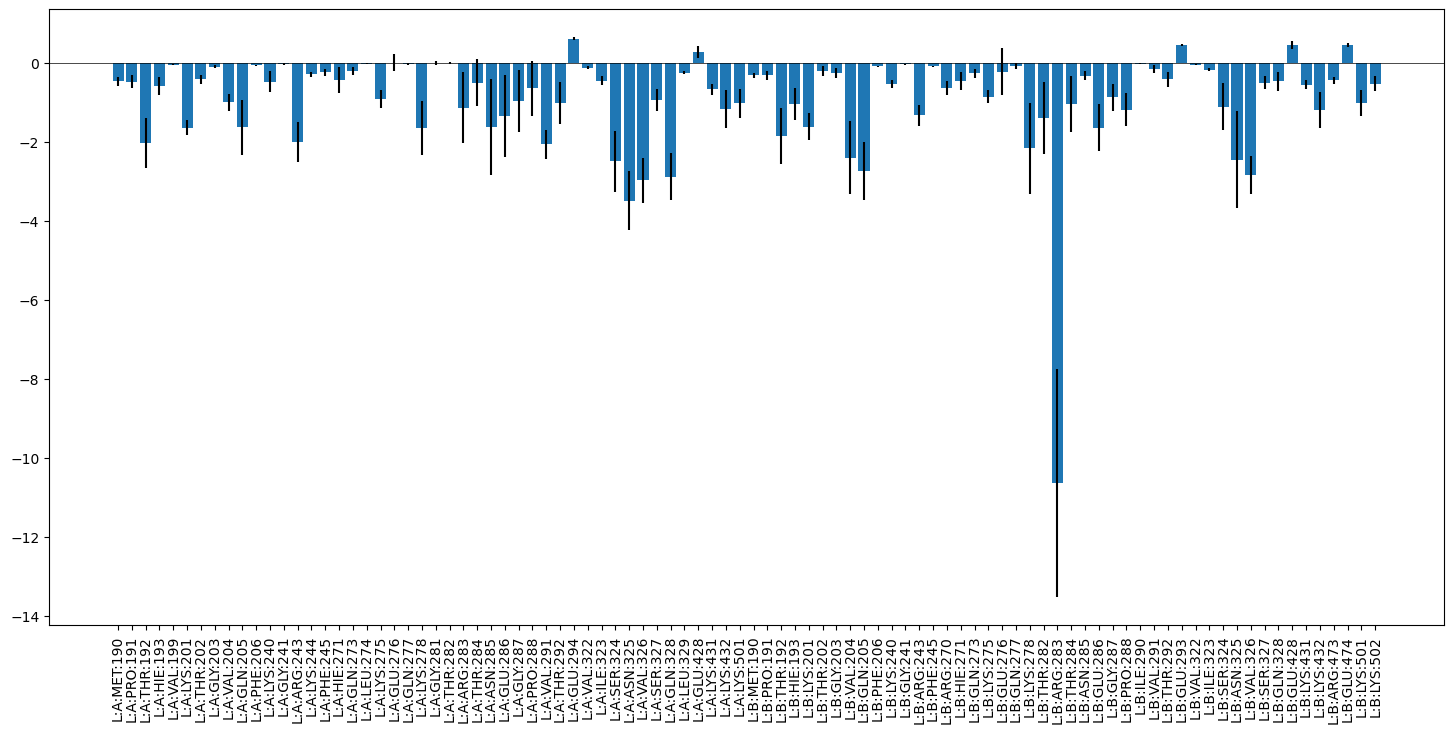

In [27]:
df = wt_decomp_summary[0][wt_decomp_summary[0]["compound"] == "L"].sort_values(by=["chain", "resid"], ascending=True)
plt.figure(figsize=(18, 8))
plt.bar(df['Residue'], df['TOTAL_mean'], yerr=df['TOTAL_std'])

plt.axhline(0, color='black', linewidth=0.5)
plt.xticks(rotation=90)
plt.show()

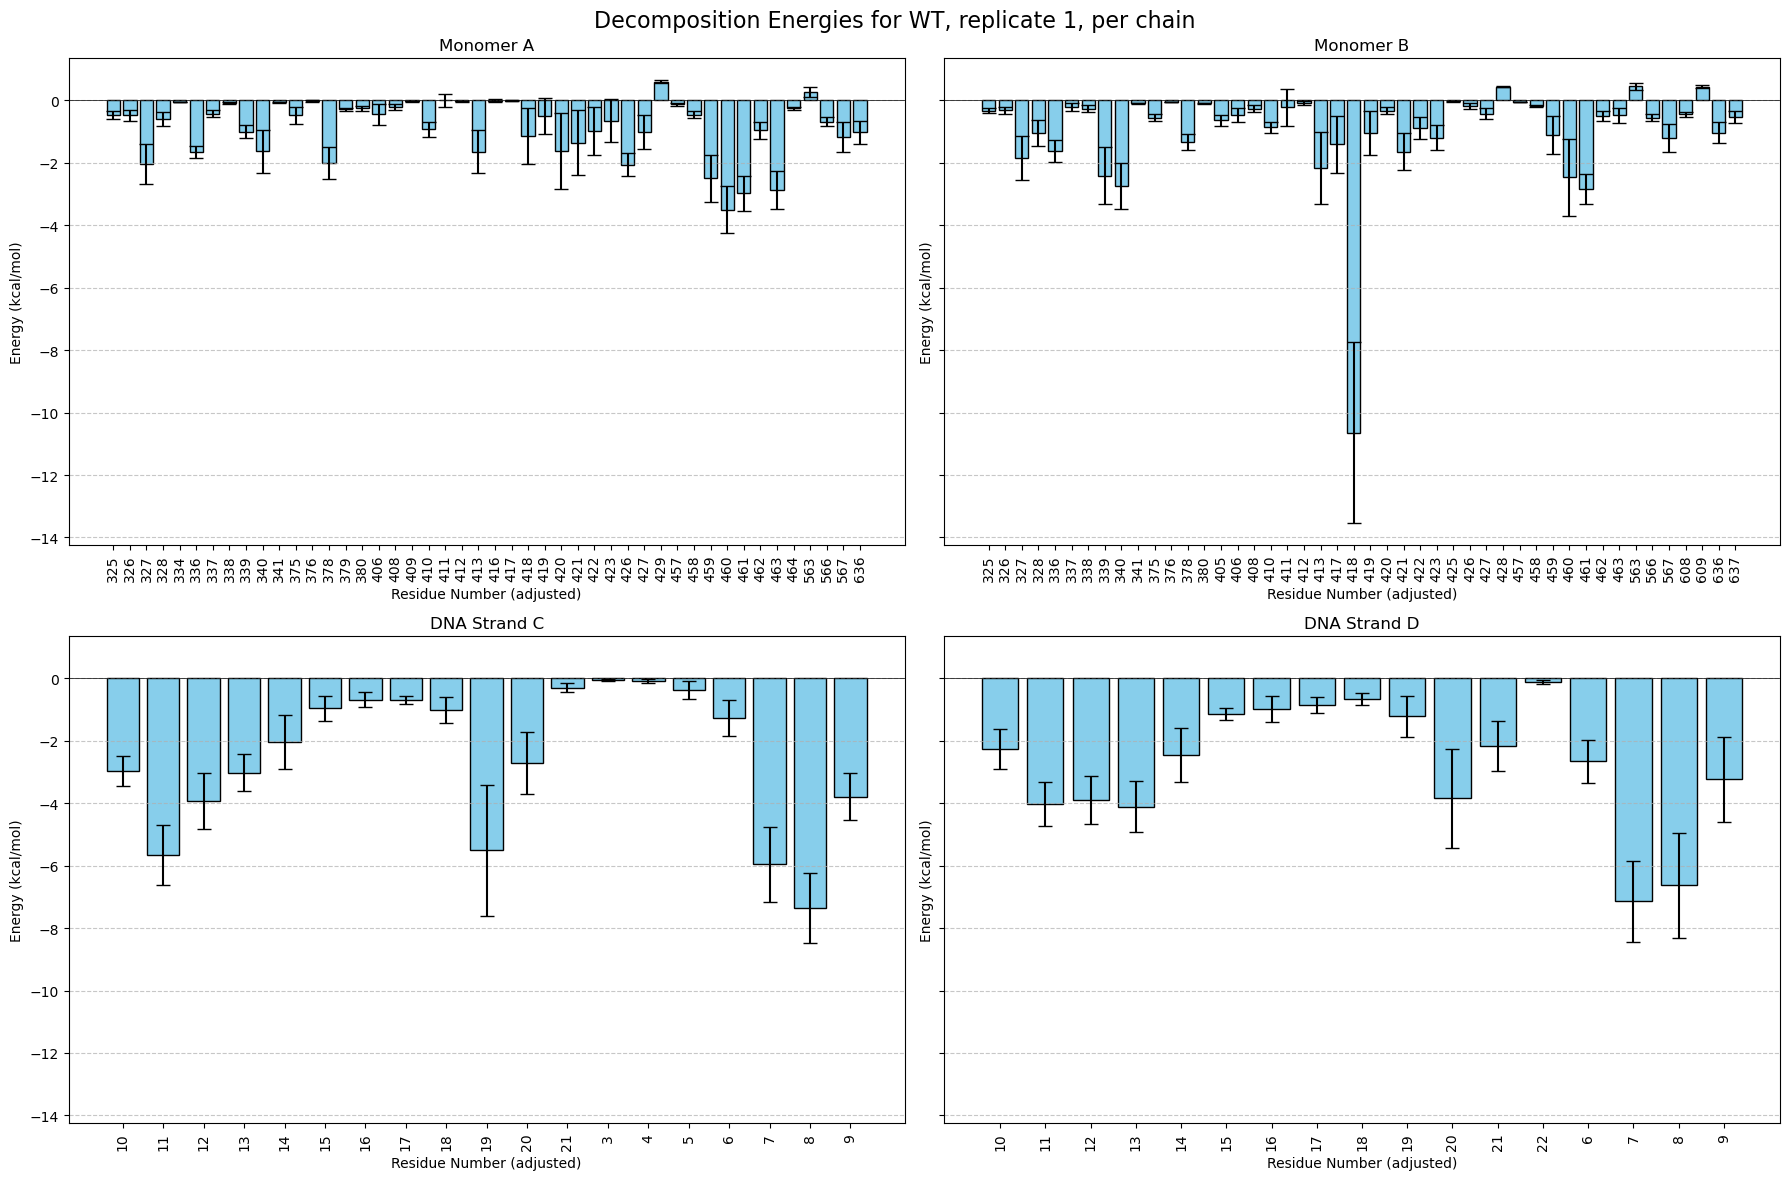

In [28]:
df_chainA = wt_decomp_summary[0][wt_decomp_summary[0]["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)
df_chainB = wt_decomp_summary[0][wt_decomp_summary[0]["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)
df_chainC = wt_decomp_summary[0][wt_decomp_summary[0]["chain"] == "C"].sort_values(by=["resid_adj"], ascending=True)
df_chainD = wt_decomp_summary[0][wt_decomp_summary[0]["chain"] == "D"].sort_values(by=["resid_adj"], ascending=True)


# Find global min and max
all_data = [
    df_chainA['TOTAL_mean'].values,
    df_chainB['TOTAL_mean'].values,
    df_chainC['TOTAL_mean'].values,
    df_chainD['TOTAL_mean'].values,
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(2, 2, figsize=(18, 12), sharey=True)
ax1, ax2, ax3, ax4 = axes.flatten()

plots = [
    (df_chainA, ax1, 'Monomer A'),
    (df_chainB, ax2, 'Monomer B'),
    (df_chainC, ax3, 'DNA Strand C'),
    (df_chainD, ax4, 'DNA Strand D'),
]

for df, ax, title in plots:
    ax.bar(df["resid_adj"], df['TOTAL_mean'], yerr=df['TOTAL_std'], capsize=5, color='skyblue', edgecolor='black')
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.set_xlabel('Residue Number (adjusted)')
    ax.tick_params(axis='x', rotation=90, labelbottom=True)
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)

plt.suptitle('Decomposition Energies for WT, replicate 1, per chain', fontsize=16)

plt.tight_layout()
plt.show()

In [29]:
wt_decomp_summary[0][wt_decomp_summary[0]["chain"] == "A"].sort_values('resid_adj')['resid_adj'].unique() 

array(['325', '326', '327', '328', '334', '336', '337', '338', '339',
       '340', '341', '375', '376', '378', '379', '380', '406', '408',
       '409', '410', '411', '412', '413', '416', '417', '418', '419',
       '420', '421', '422', '423', '426', '427', '429', '457', '458',
       '459', '460', '461', '462', '463', '464', '563', '566', '567',
       '636'], dtype=object)

In [30]:
wt_decomp_summary[0][wt_decomp_summary[0]["chain"] == "B"].sort_values('resid_adj')['resid_adj'].unique() 

array(['325', '326', '327', '328', '336', '337', '338', '339', '340',
       '341', '375', '376', '378', '380', '405', '406', '408', '410',
       '411', '412', '413', '417', '418', '419', '420', '421', '422',
       '423', '425', '426', '427', '428', '457', '458', '459', '460',
       '461', '462', '463', '563', '566', '567', '608', '609', '636',
       '637'], dtype=object)

In [31]:
wt_decomp_summary[0][wt_decomp_summary[0]["chain"] == "A"].sort_values('resid_adj')['resid_adj'].unique()  == wt_decomp_summary[0][wt_decomp_summary[0]["chain"] == "B"].sort_values('resid_adj')['resid_adj'].unique() 

array([ True,  True,  True,  True, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False])

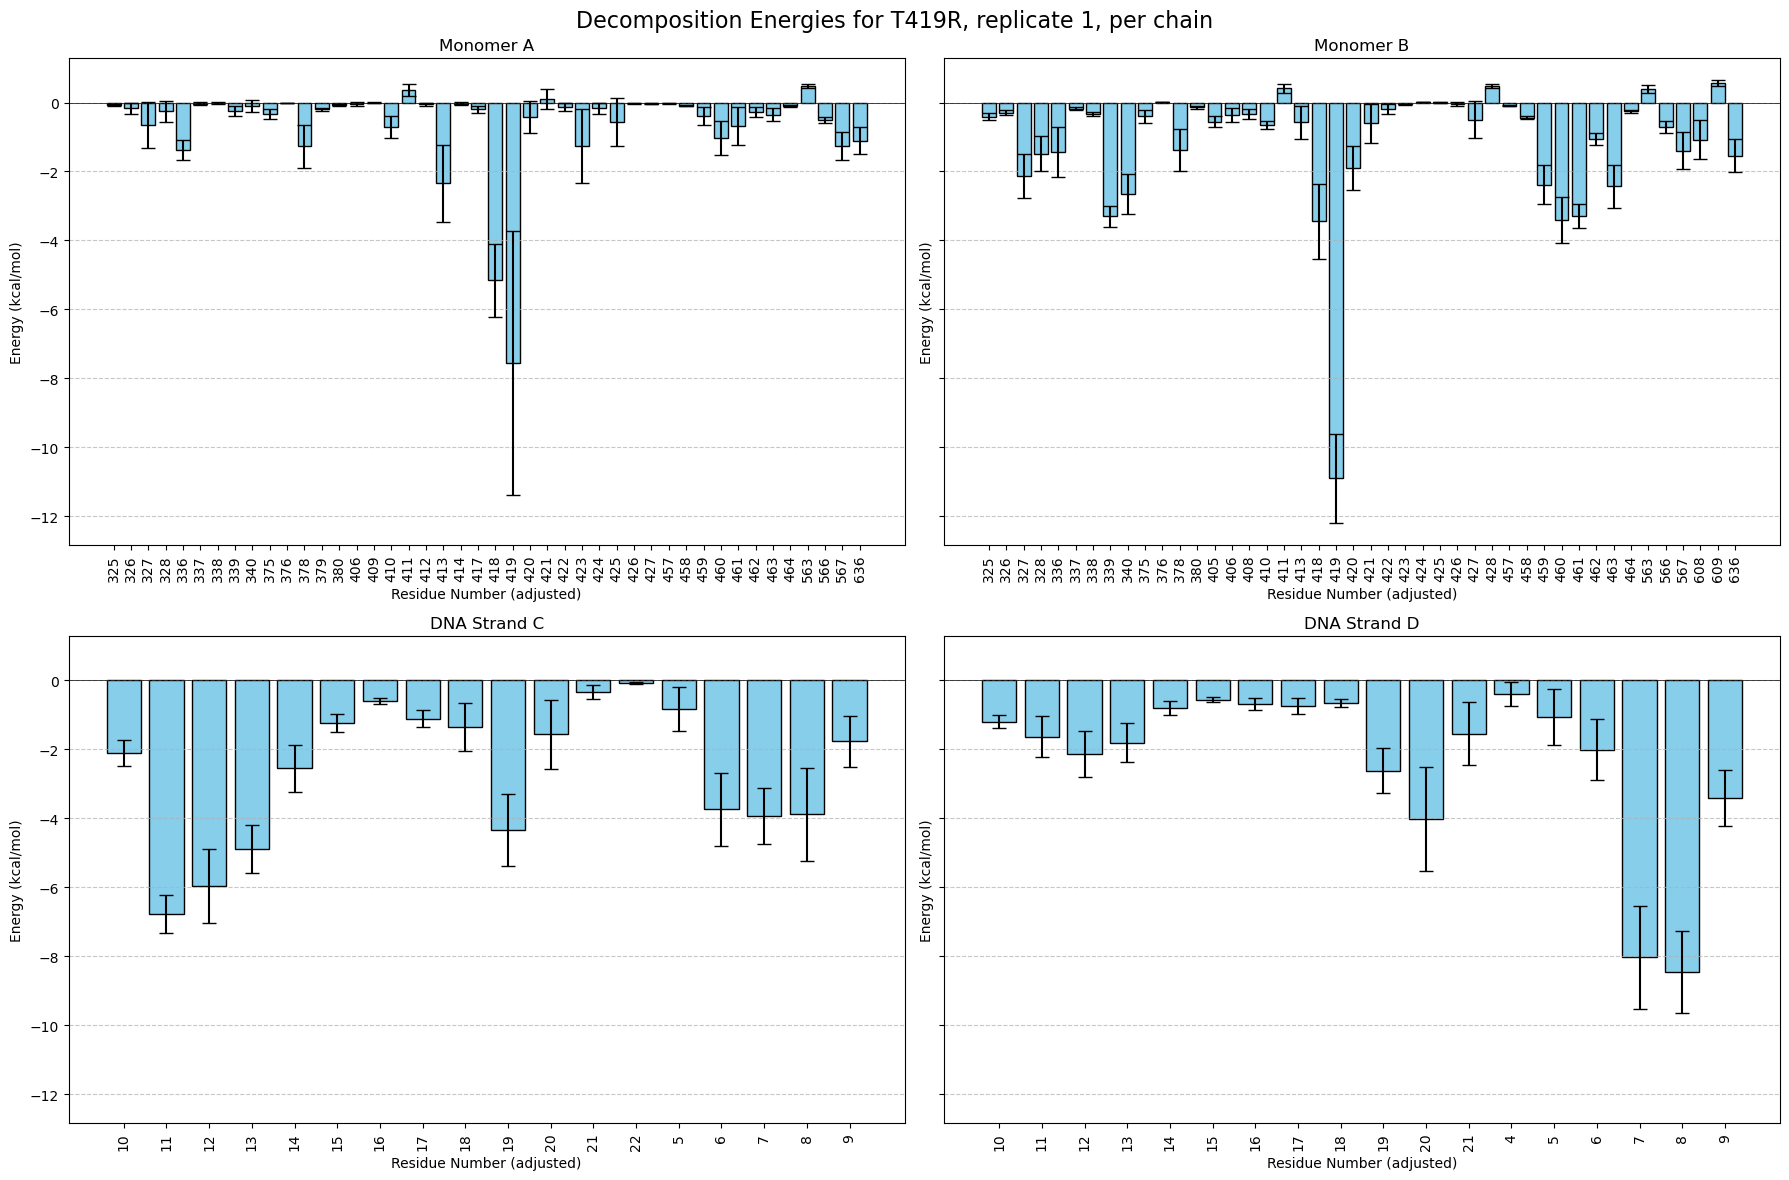

In [32]:

df_chainA = T419R_decomp_summary[0][T419R_decomp_summary[0]["chain"] == "A"].sort_values(by=["resid"], ascending=True)
df_chainB = T419R_decomp_summary[0][T419R_decomp_summary[0]["chain"] == "B"].sort_values(by=["resid"], ascending=True)
df_chainC = T419R_decomp_summary[0][T419R_decomp_summary[0]["chain"] == "C"].sort_values(by=["resid"], ascending=True)
df_chainD = T419R_decomp_summary[0][T419R_decomp_summary[0]["chain"] == "D"].sort_values(by=["resid"], ascending=True)


# Find global min and max
all_data = [
    df_chainA['TOTAL_mean'].values,
    df_chainB['TOTAL_mean'].values,
    df_chainC['TOTAL_mean'].values,
    df_chainD['TOTAL_mean'].values,
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(2, 2, figsize=(18, 12), sharey=True)
ax1, ax2, ax3, ax4 = axes.flatten()

plots = [
    (df_chainA, ax1, 'Monomer A'),
    (df_chainB, ax2, 'Monomer B'),
    (df_chainC, ax3, 'DNA Strand C'),
    (df_chainD, ax4, 'DNA Strand D'),
]

for df, ax, title in plots:
    ax.bar(df['resid_adj'], df['TOTAL_mean'], yerr=df['TOTAL_std'], capsize=5, color='skyblue', edgecolor='black')
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.set_xlabel('Residue Number (adjusted)')
    ax.tick_params(axis='x', rotation=90, labelbottom=True)
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)

plt.suptitle('Decomposition Energies for T419R, replicate 1, per chain', fontsize=16)

plt.tight_layout()
plt.show()

There might be significant differences between monomers for corresponding residues, that is, residues with the same number. Also note that MMPBSA filtered out different residues in each monomer, likely due to their energy values close to zero. 
It is challenging to draw conclusions from the separate replicate data and it is advisable to aggregate it.

### By mutation (combining replicates)

In [33]:
def combine_decomp(dfs):
    
    df = pd.concat(dfs)

    energy_terms = ['van der Waals', 'Electrostatic', 
        'Polar Solvation', 'Non-Polar Solv.', 'TOTAL'
    ]
    
    # Columns for means and standard deviations
    mean_cols = [f"{term}_mean" for term in energy_terms]
    std_cols = [f"{term}_std" for term in energy_terms]
    
    # Group by residue identifiers
    group_cols = ['Residue', 'compound', 'chain', 'resnm', 'resid', 'resid_adj']
    df_grouped = df.groupby(group_cols)
    
    result_data = []
    
    # Process each group (residue)
    for name, group in df_grouped:
        # Dictionary to store results for this group
        group_result = dict(zip(group_cols, name))
        
        # Calculate mean and pooled std for each energy term
        for mean_col, std_col in zip(mean_cols, std_cols):
            # Mean
            combined_mean = group[mean_col].mean()
            
            # Pooled standard deviation
            stds = group[std_col]
            variances = [s**2 for s in stds]
            pooled_variance = np.mean(variances)  # Average variances
            pooled_std = np.sqrt(pooled_variance) if pooled_variance > 0 else 0.0
            
            group_result[mean_col] = combined_mean
            group_result[std_col] = pooled_std
        
        result_data.append(group_result)
    
    combined_df = pd.DataFrame(result_data)
    
    # Reorder columns to match input structure
    output_cols = group_cols + [col for term in energy_terms for col in [f"{term}_mean", f"{term}_std"]]
    combined_df = combined_df[output_cols]
    
    return combined_df

In [34]:
wt_decomp_combined_df = combine_decomp(wt_decomp_summary)
T419R_decomp_combined_df = combine_decomp(T419R_decomp_summary)

In [35]:
wt_decomp_combined_df.head()

,Residue,compound,chain,resnm,resid,resid_adj,van der Waals_mean,van der Waals_std,Electrostatic_mean,Electrostatic_std,Polar Solvation_mean,Polar Solvation_std,Non-Polar Solv._mean,Non-Polar Solv._std,TOTAL_mean,TOTAL_std
0,L:A:ALA:280,L,A,ALA,280,415,-0.036178,0.029370,-0.066886,0.380156,0.069052,0.356568,-0.000709,0.007166,-0.034481,0.045270
1,L:A:ARG:243,L,A,ARG,243,378,-0.780729,0.564764,-33.489541,0.633727,32.407764,0.549420,-0.135542,0.034170,-1.998114,0.521936
2,L:A:ARG:283,L,A,ARG,283,418,-1.408623,1.126137,-28.401906,3.768551,27.720366,3.498618,-0.309102,0.238257,-2.399155,1.443181
3,L:A:ASN:279,L,A,ASN,279,414,-0.045719,0.027597,0.487874,0.477485,-0.449331,0.451858,-0.000240,0.004210,-0.007495,0.039454
4,L:A:ASN:285,L,A,ASN,285,420,-1.347026,0.839330,-0.576391,0.827235,0.626653,0.743328,-0.206131,0.141764,-1.502884,0.974604


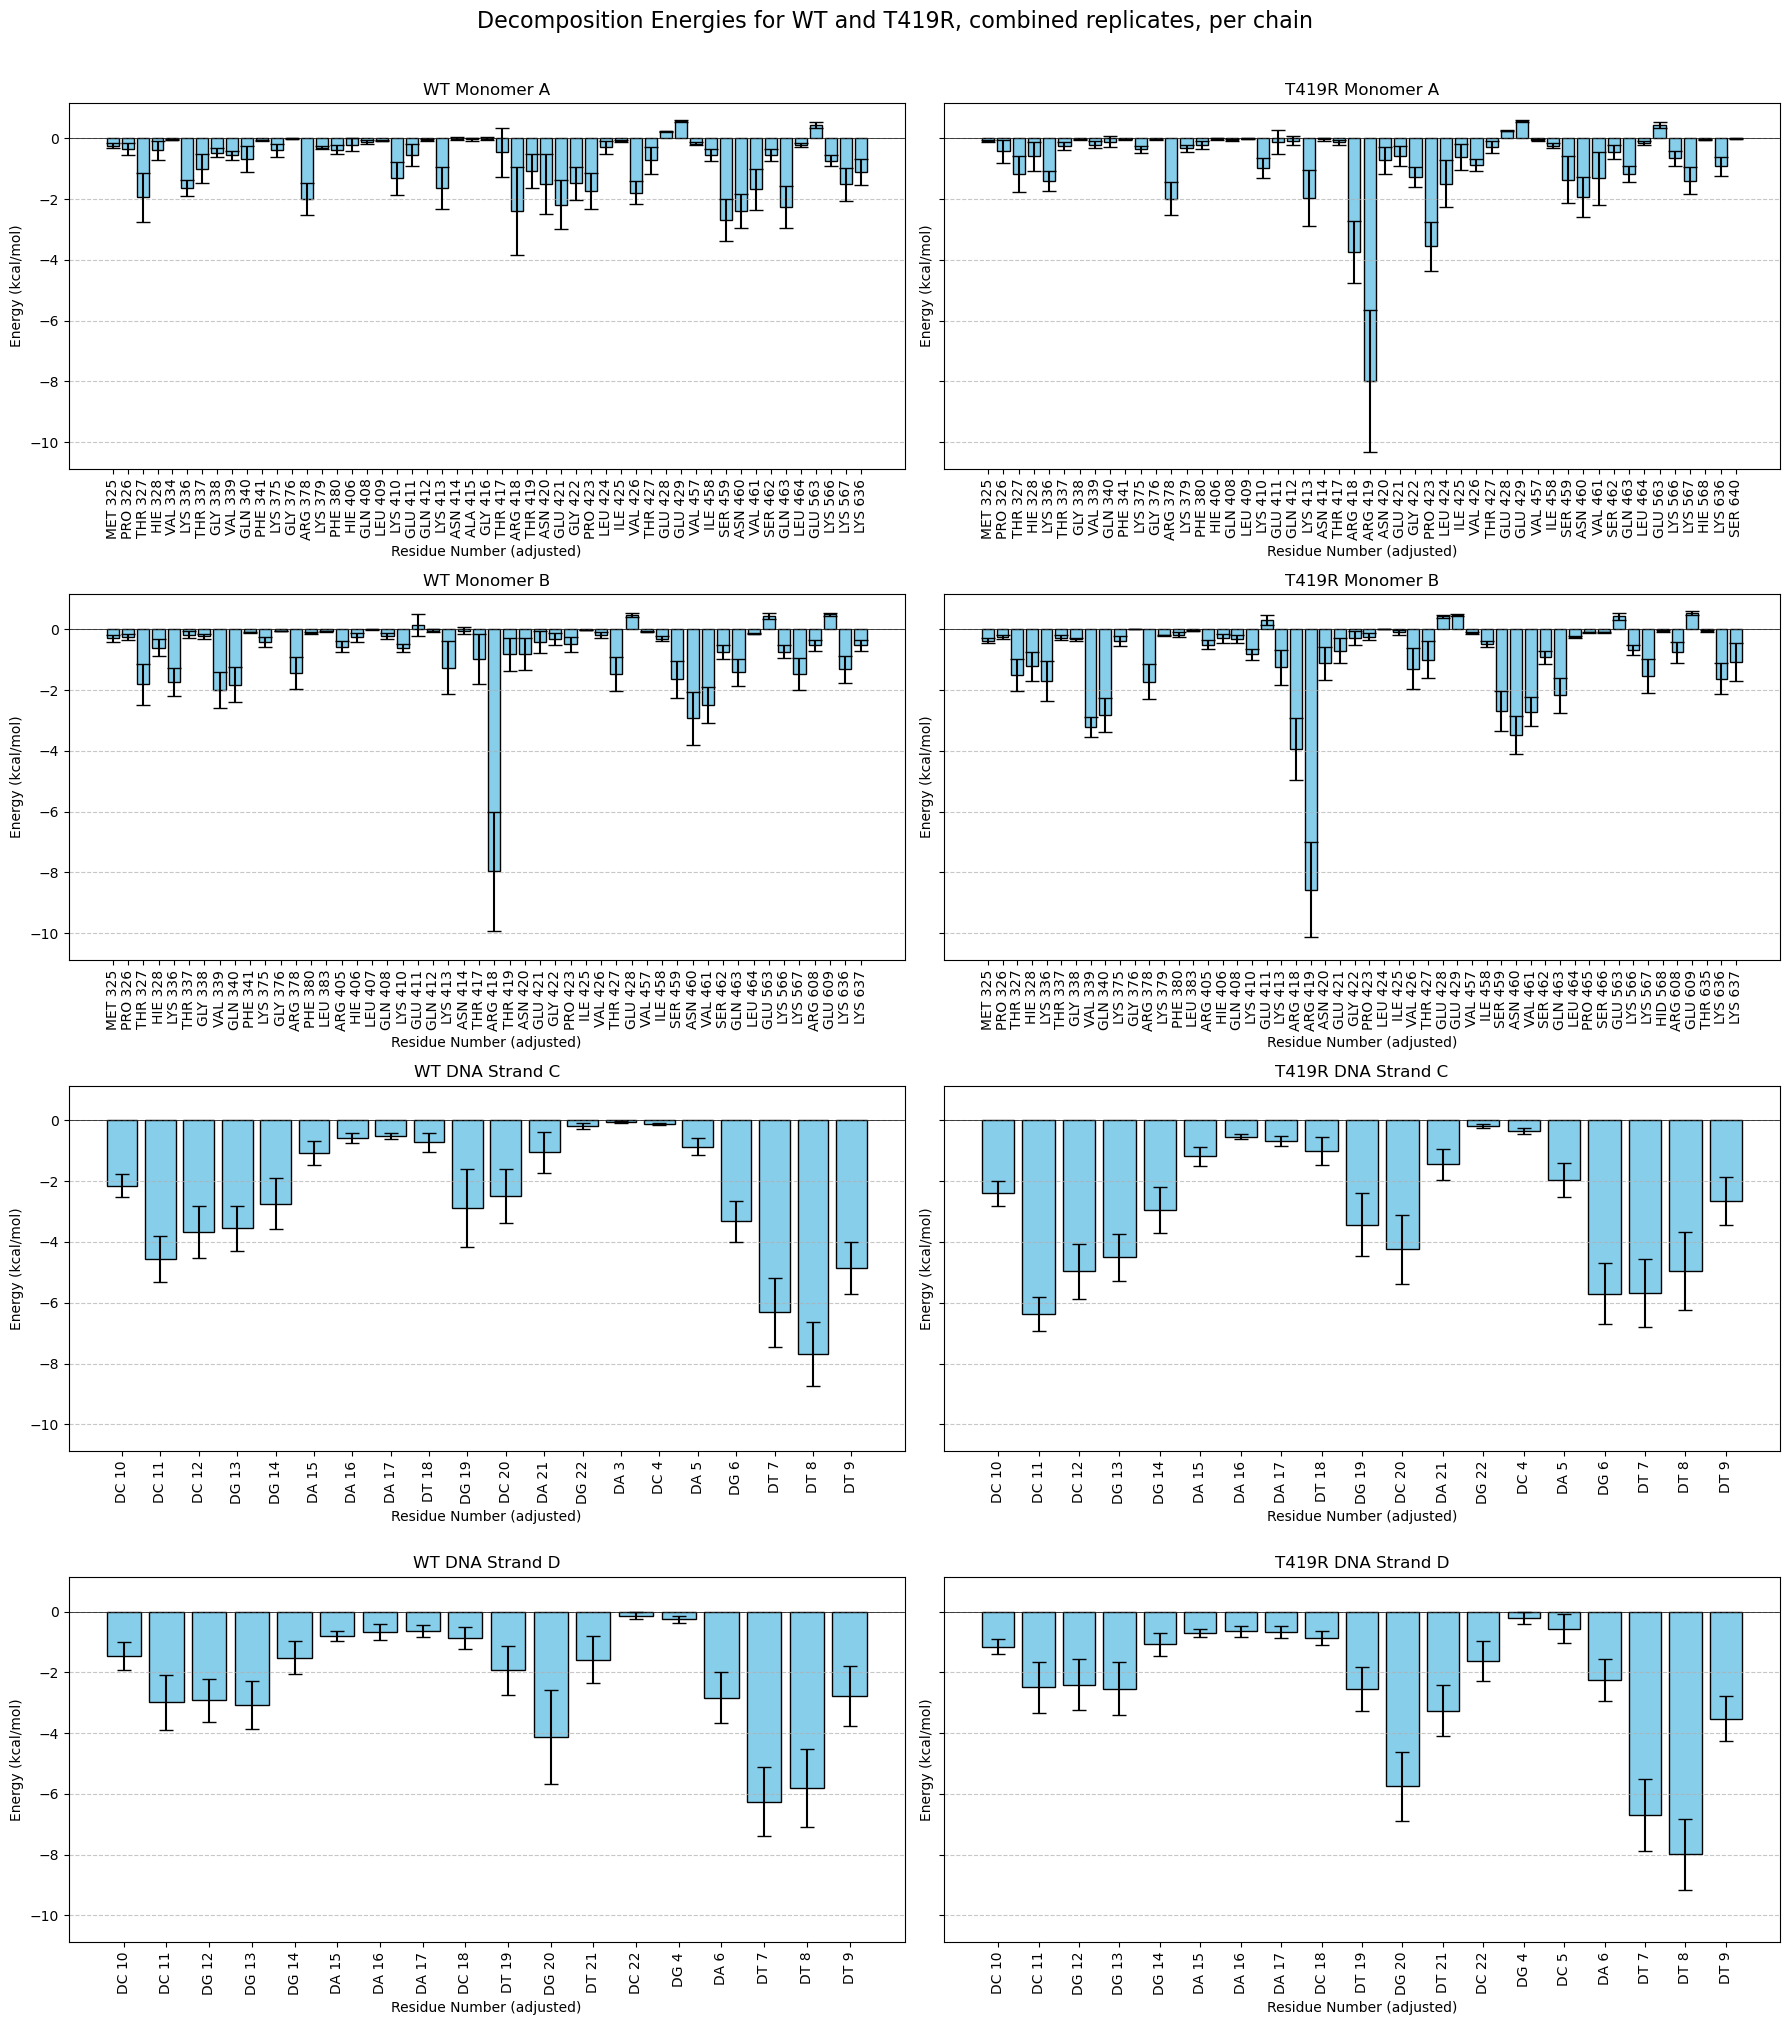

In [36]:
df_wt_monoA = wt_decomp_combined_df[wt_decomp_combined_df["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)
df_T419R_monoA = T419R_decomp_combined_df[T419R_decomp_combined_df["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)

df_wt_monoB = wt_decomp_combined_df[wt_decomp_combined_df["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)
df_T419R_monoB = T419R_decomp_combined_df[T419R_decomp_combined_df["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)

df_wt_dnaC = wt_decomp_combined_df[wt_decomp_combined_df["chain"] == "C"].sort_values(by=["resid_adj"], ascending=True)
df_T419R_dnaC = T419R_decomp_combined_df[T419R_decomp_combined_df["chain"] == "C"].sort_values(by=["resid_adj"], ascending=True)

df_wt_dnaD = wt_decomp_combined_df[wt_decomp_combined_df["chain"] == "D"].sort_values(by=["resid_adj"], ascending=True)
df_T419R_dnaD = T419R_decomp_combined_df[T419R_decomp_combined_df["chain"] == "D"].sort_values(by=["resid_adj"], ascending=True)

# Find global min and max
all_data = [
    df_wt_monoA['TOTAL_mean'].values,
    df_T419R_monoA['TOTAL_mean'].values,
    df_wt_monoB['TOTAL_mean'].values,
    df_T419R_monoB['TOTAL_mean'].values,
    df_wt_dnaC['TOTAL_mean'].values,
    df_T419R_dnaC['TOTAL_mean'].values,
    df_wt_dnaD['TOTAL_mean'].values,
    df_T419R_dnaD['TOTAL_mean'].values,
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(4, 2, figsize=(18, 20), sharey=True)
ax1, ax2, ax3, ax4, ax5, ax6, ax7, ax8 = axes.flatten()

plots = [
    (df_wt_monoA, ax1, 'WT Monomer A'),
    (df_T419R_monoA, ax2, 'T419R Monomer A'),
    (df_wt_monoB, ax3, 'WT Monomer B'),
    (df_T419R_monoB, ax4, 'T419R Monomer B'),
    (df_wt_dnaC, ax5, 'WT DNA Strand C'),   
    (df_T419R_dnaC, ax6, 'T419R DNA Strand C'),
    (df_wt_dnaD, ax7, 'WT DNA Strand D'),
    (df_T419R_dnaD, ax8, 'T419R DNA Strand D'),
]

for df, ax, title in plots:
    ax.bar(df['resid_adj'], df['TOTAL_mean'], yerr=df['TOTAL_std'], capsize=5, color='skyblue', edgecolor='black')
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.set_xlabel('Residue Number (adjusted)')
    ax.tick_params(axis='x', rotation=90, labelbottom=True,)
    ax.set_xticks(df['resid_adj'])
    ax.set_xticklabels([f"{resnm} {resid}" for resnm, resid in zip(df['resnm'], df['resid_adj'])])
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)

plt.suptitle('Decomposition Energies for WT and T419R, combined replicates, per chain', fontsize=16, y=1.01)

plt.tight_layout()
plt.show()

Zoom in on the mutated residue, 419. This are has visible differences between WT and T419R in both monomers.

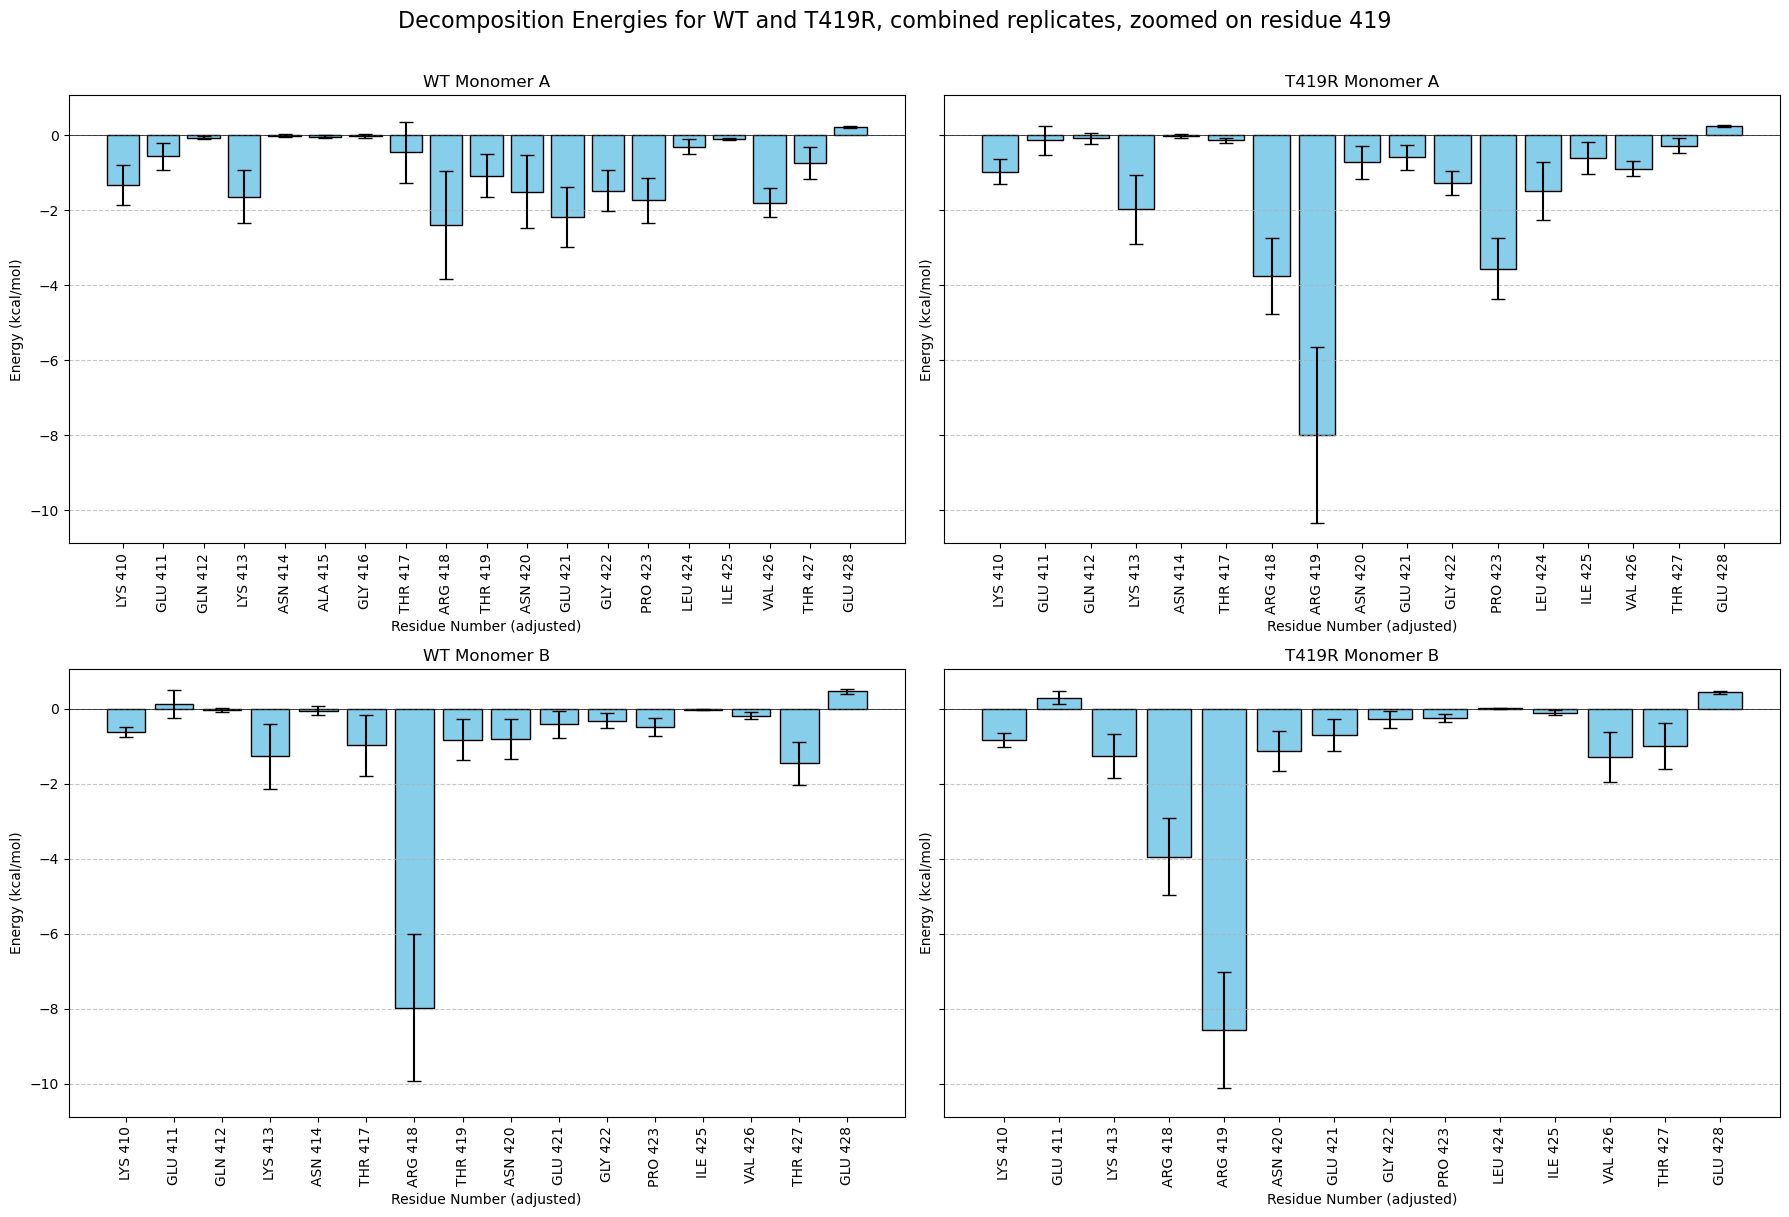

In [37]:
df_wt_monoA = wt_decomp_combined_df[wt_decomp_combined_df["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)
df_T419R_monoA = T419R_decomp_combined_df[T419R_decomp_combined_df["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)

df_wt_monoB = wt_decomp_combined_df[wt_decomp_combined_df["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)
df_T419R_monoB = T419R_decomp_combined_df[T419R_decomp_combined_df["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)

# Find global min and max
all_data = [
    df_wt_monoA['TOTAL_mean'].values,
    df_T419R_monoA['TOTAL_mean'].values,
    df_wt_monoB['TOTAL_mean'].values,
    df_T419R_monoB['TOTAL_mean'].values,
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(2, 2, figsize=(18, 12), sharey=True)
ax1, ax2, ax3, ax4 = axes.flatten()

plots = [
    (df_wt_monoA, ax1, 'WT Monomer A'),
    (df_T419R_monoA, ax2, 'T419R Monomer A'),
    (df_wt_monoB, ax3, 'WT Monomer B'),
    (df_T419R_monoB, ax4, 'T419R Monomer B'),
]

for df, ax, title in plots:
    filtered_df = df[(df['resid_adj'].astype(int) > 409) & (df['resid_adj'].astype(int) < 429)]
    ax.bar(filtered_df['resid_adj'], filtered_df['TOTAL_mean'], yerr=filtered_df['TOTAL_std'], capsize=5, color='skyblue', edgecolor='black')
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.set_xlabel('Residue Number (adjusted)')
    ax.tick_params(axis='x', rotation=90, labelbottom=True,)
    ax.set_xticks(filtered_df['resid_adj'])
    ax.set_xticklabels([f"{resnm} {resid}" for resnm, resid in zip(filtered_df['resnm'], filtered_df['resid_adj'])])
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)

plt.suptitle('Decomposition Energies for WT and T419R, combined replicates, zoomed on residue 419', fontsize=16, y=1.01)

plt.tight_layout()
plt.show()

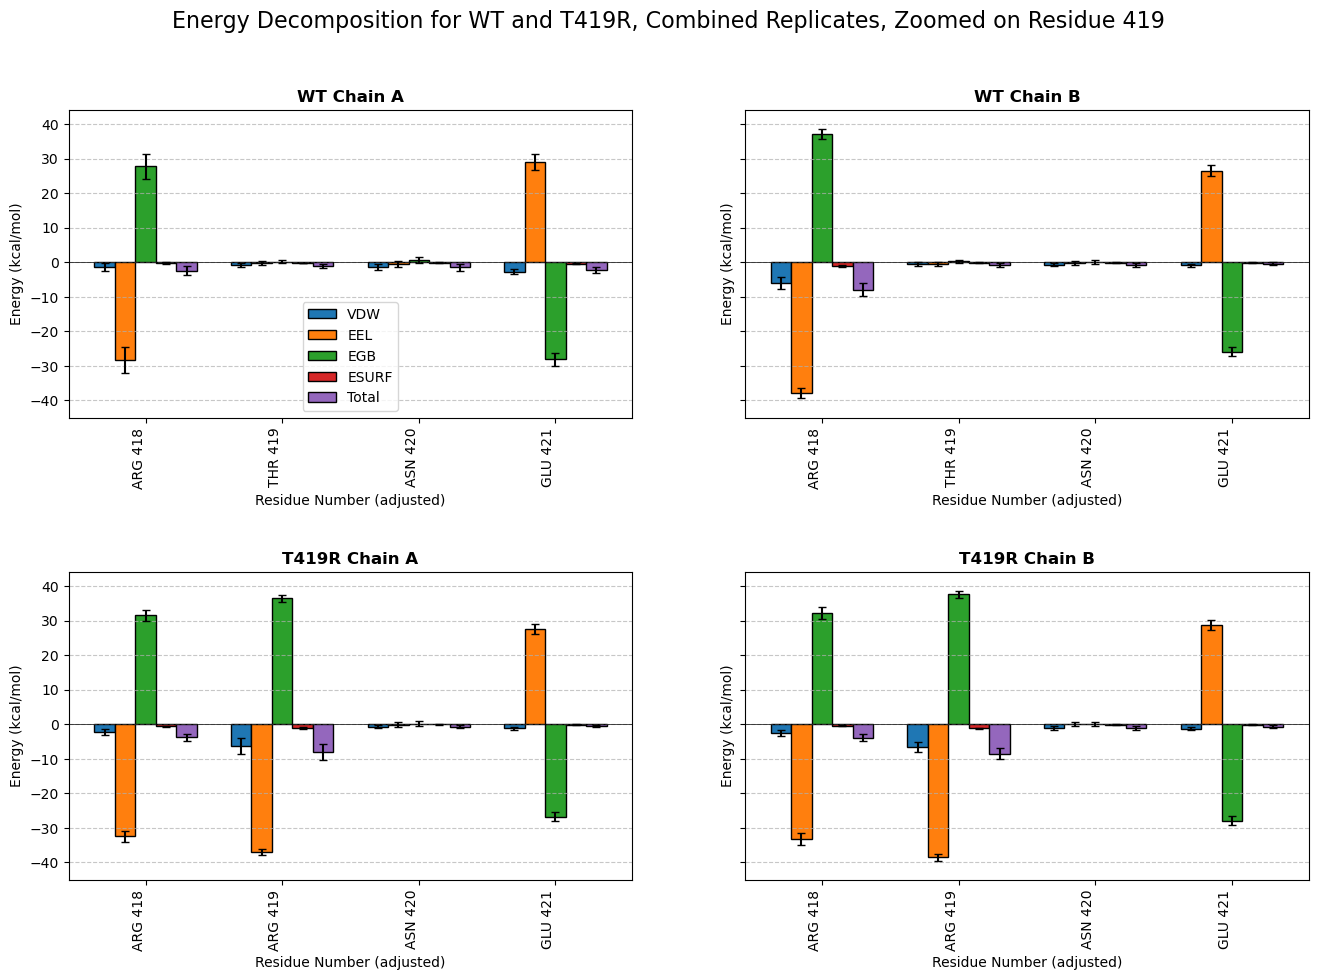

In [40]:
df_wt_monoA = wt_decomp_combined_df[wt_decomp_combined_df["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)
df_T419R_monoA = T419R_decomp_combined_df[T419R_decomp_combined_df["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)

df_wt_monoB = wt_decomp_combined_df[wt_decomp_combined_df["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)
df_T419R_monoB = T419R_decomp_combined_df[T419R_decomp_combined_df["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)

# Define energy terms and their corresponding std columns
energy_terms = [
    'van der Waals_mean', 'Electrostatic_mean', 'Polar Solvation_mean',
    'Non-Polar Solv._mean', 'TOTAL_mean'
]
std_terms = [
    'van der Waals_std', 'Electrostatic_std', 'Polar Solvation_std',
    'Non-Polar Solv._std', 'TOTAL_std'
]

# Find global min and max across all energy terms
all_data = []
for df in [df_wt_monoA, df_T419R_monoA, df_wt_monoB, df_T419R_monoB]:
    for term in energy_terms:
        all_data.append(df[term].values)
global_min = min([np.nanmin(data) for data in all_data]) * 1.1  # Add 10% buffer
global_max = max([np.nanmax(data) for data in all_data]) * 1.1  # Add 10% buffer

# Create figure and subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharey=True)
ax1, ax2, ax3, ax4 = axes.flatten()

# Define plots
plots = [
    (df_wt_monoA, ax1, 'WT Chain A'),
    (df_wt_monoB, ax2, 'WT Chain B'),
    (df_T419R_monoA, ax3, 'T419R Chain A'),
    (df_T419R_monoB, ax4, 'T419R Chain B'),
]

# Plotting parameters
n_terms = len(energy_terms)  # Number of energy terms (5)
bar_width = 0.15  # Width of each bar
labels = ['VDW', 'EEL', 'EGB', 'ESURF', 'Total']  # Short labels for legend

for df, ax, title in plots:
    # Filter for residues in the range 416–424
    filtered_df = df[(df['resid_adj'].astype(int) > 417) & (df['resid_adj'].astype(int) < 422)]
    
    # Get residue positions and labels
    residues = filtered_df['resid_adj'].values
    res_labels = [f"{resnm} {resid}" for resnm, resid in zip(filtered_df['resnm'], filtered_df['resid_adj'])]
    n_residues = len(residues)
    
    # Set x positions for bars
    x = np.arange(n_residues)  # Base positions for residues
    for i, (term, std, label) in enumerate(zip(energy_terms, std_terms, labels)):
        # Calculate x positions for this term's bars
        x_pos = x + i * bar_width - (n_terms - 1) * bar_width / 2
        # Plot bars with error bars
        ax.bar(
            x_pos,
            filtered_df[term],
            yerr=filtered_df[std],
            width=bar_width,
            edgecolor='black',
            capsize=3,
            label=label if ax == ax1 else None  # Add legend only on first subplot
        )
    
    # Customize axes
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel('Energy (kcal/mol)')
    ax.set_xlabel('Residue Number (adjusted)')
    ax.set_xticks(x)
    ax.set_xticklabels(res_labels, rotation=90, ha='right')
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)
    ax.set_ylim(global_min, global_max)  # Set consistent y-limits

# Add legend to the first subplot
ax1.legend(loc='best')

# Add suptitle and adjust layout
plt.suptitle('Energy Decomposition for WT and T419R, Combined Replicates, Zoomed on Residue 419', fontsize=16)


plt.subplots_adjust(hspace=0.5)
plt.show()

#### Interpretation - Differences in residue 419

There is a clear difference between WT and T419R at residue 419 in both monomers. In WT, both EEL and EGB are close to 0 kcal/mol, while in T419 they means are close to 38 kcal/mol and -38 kcal/mol, respectively. This opposing values are close to cancelling each other out, resulting in a limited effect on the total energy. The differences in total energy between WT and T419R at this residue can therefore be mostly attributed to Van der Waals interactions and, to a lesser extent, to surface non-polar solvation energy, both of which have lower values (stronger binding) in T419R.

To analyze wether this difference between WT and T419R is limited to the mutated residue, we can analyze the distribution of the energy metrics.

In [ ]:
# Merge WT and T419R DataFrames on 'resid_adj' and 'chain' to get common residues
common_df = wt_decomp_combined_df[['Residue', 'resid_adj', 'chain', 'Electrostatic_mean', 'Polar Solvation_mean', 'van der Waals_mean', 'Non-Polar Solv._mean']].merge(
    T419R_decomp_combined_df[['Residue', 'resid_adj', 'chain', 'Electrostatic_mean', 'Polar Solvation_mean', 'van der Waals_mean', 'Non-Polar Solv._mean']],
    on=['resid_adj', 'chain'],
    suffixes=('_WT', '_T419R')
)

# Calculate the differences (WT - T419R)
common_df['EEL_diff'] = common_df['Electrostatic_mean_WT'] - common_df['Electrostatic_mean_T419R']
common_df['VDW_diff'] = common_df['van der Waals_mean_WT'] - common_df['van der Waals_mean_T419R']
common_df['EGB_diff'] = common_df['Polar Solvation_mean_WT'] - common_df['Polar Solvation_mean_T419R']
common_df['ESURF_diff'] = common_df['Non-Polar Solv._mean_WT'] - common_df['Non-Polar Solv._mean_T419R']

Residues not in both dfs

In [55]:
# Perform an outer merge to include all residues and their associated columns
merged_df = wt_decomp_combined_df[['resid_adj', 'chain', 'Electrostatic_mean', 'Polar Solvation_mean', 'van der Waals_mean', 'Non-Polar Solv._mean']].merge(
    T419R_decomp_combined_df[['resid_adj', 'chain', 'Electrostatic_mean', 'Polar Solvation_mean', 'van der Waals_mean', 'Non-Polar Solv._mean']],
    on=['resid_adj', 'chain'],
    how='outer',
    indicator=True,
    suffixes=('_WT', '_S466R')
)

# Filter for residues that are only in one DataFrame
non_common_df = merged_df[merged_df['_merge'] != 'both'].copy()

# Create a column to indicate which DataFrame the residue is from
non_common_df['Source'] = non_common_df['_merge'].map({
    'left_only': 'WT',
    'right_only': 'T419R'
})

# Create consolidated columns for the energy terms, prioritizing WT or S466R values
non_common_df['Electrostatic_mean'] = non_common_df['Electrostatic_mean_WT'].fillna(non_common_df['Electrostatic_mean_S466R'])
non_common_df['Polar Solvation_mean'] = non_common_df['Polar Solvation_mean_WT'].fillna(non_common_df['Polar Solvation_mean_S466R'])
non_common_df['van der Waals_mean'] = non_common_df['van der Waals_mean_WT'].fillna(non_common_df['van der Waals_mean_S466R'])
non_common_df['Non-Polar Solv._mean'] = non_common_df['Non-Polar Solv._mean_WT'].fillna(non_common_df['Non-Polar Solv._mean_S466R'])

# Select relevant columns for the final table
result_df = non_common_df[['resid_adj', 'chain', 'Source', 'Electrostatic_mean', 'Polar Solvation_mean', 'van der Waals_mean', 'Non-Polar Solv._mean']]

# Print the table
result_df

,resid_adj,chain,Source,Electrostatic_mean,Polar Solvation_mean,van der Waals_mean,Non-Polar Solv._mean
0,415,A,WT,-0.066886,0.069052,-0.036178,-0.000709
17,416,A,WT,0.048882,-0.044152,-0.014401,-0.001048
46,334,A,WT,-0.056023,0.052959,-0.044586,0.000000
55,414,B,WT,0.103932,-0.088942,-0.055379,-0.006766
60,412,B,WT,0.317246,-0.282660,-0.074162,-0.002136
75,407,B,WT,0.806527,-0.753892,-0.054152,0.000000
86,341,B,WT,0.274421,-0.250120,-0.114721,0.000000
94,417,B,WT,-0.661023,0.570963,-0.768453,-0.113972
105,3,C,WT,0.504731,-0.507445,-0.049731,0.000000
139,568,A,T419R,-0.425639,0.412894,-0.033613,-0.000319


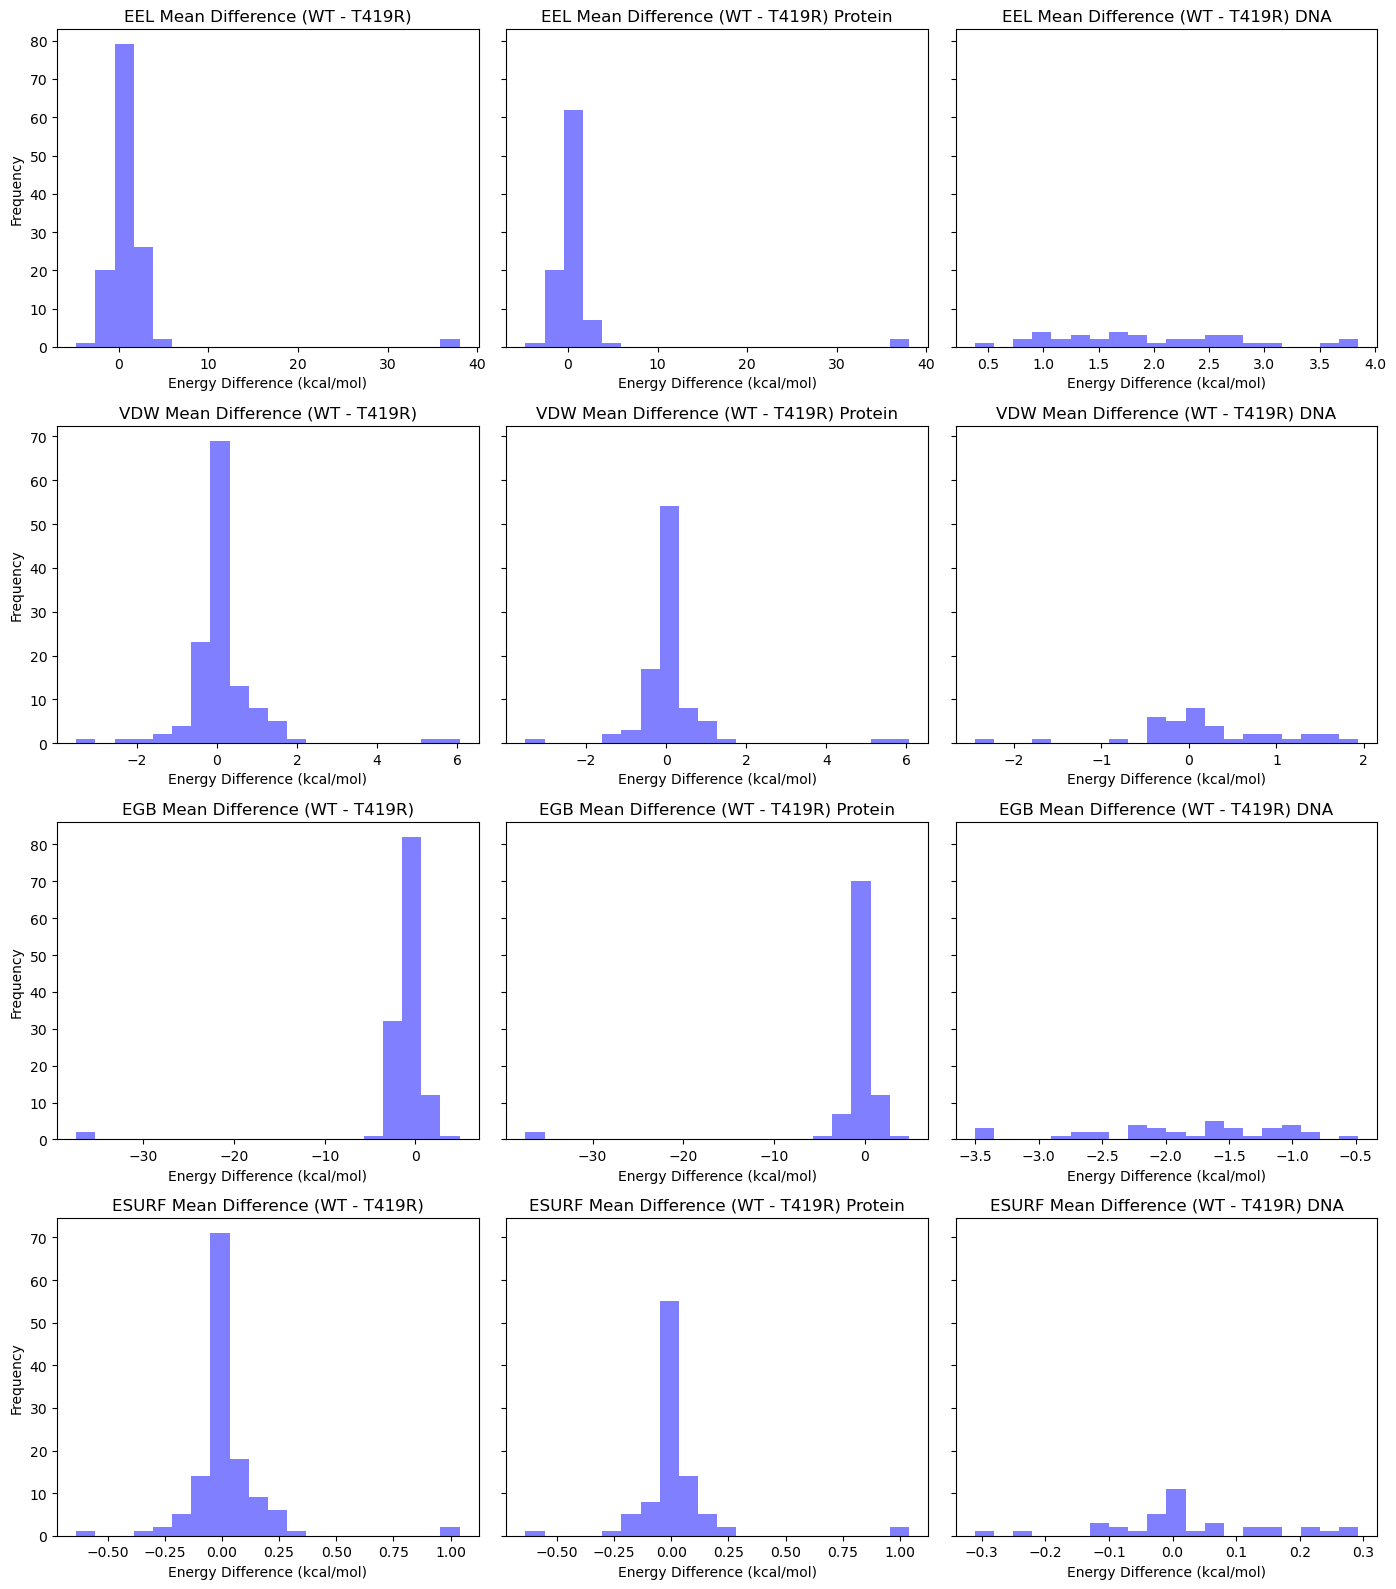

In [38]:
# columns ending in '_diff'
diff_columns = common_df.filter(like='_diff').columns
n_rows = len(diff_columns)

fig, axes = plt.subplots(n_rows, 3, figsize=(14, 4 * n_rows), sharey='row', squeeze=False)

for row, diff_col in enumerate(diff_columns):
    # Extract the energy term name
    term_name = diff_col.replace('_diff', '')
    
    # All residues
    axes[row, 0].hist(common_df[diff_col], bins=20, alpha=0.5, color='blue')
    axes[row, 0].set_title(f'{term_name} Mean Difference (WT - T419R)')
    axes[row, 0].set_xlabel('Energy Difference (kcal/mol)')
    axes[row, 0].set_ylabel('Frequency')
    
    # Protein chains (A, B)
    axes[row, 1].hist(common_df[diff_col][common_df['chain'].isin(['A', 'B'])], bins=20, alpha=0.5, color='blue')
    axes[row, 1].set_title(f'{term_name} Mean Difference (WT - T419R) Protein')
    axes[row, 1].set_xlabel('Energy Difference (kcal/mol)')
    
    # DNA chains (C, D)
    axes[row, 2].hist(common_df[diff_col][common_df['chain'].isin(['C', 'D'])], bins=20, alpha=0.5, color='blue')
    axes[row, 2].set_title(f'{term_name} Mean Difference (WT - T419R) DNA')
    axes[row, 2].set_xlabel('Energy Difference (kcal/mol)')

plt.tight_layout()
plt.show()

EEL outlyers

In [39]:
common_df[common_df['EEL_diff'] > 4][['resid_adj', 'chain', 'Electrostatic_mean_WT', 'Electrostatic_mean_T419R', 'EEL_diff']].sort_values('EEL_diff', ascending=False)

,resid_adj,chain,Electrostatic_mean_WT,Electrostatic_mean_T419R,EEL_diff
87,419,B,-0.472325,-38.518347,38.046021
42,419,A,-0.134963,-37.040299,36.905336
1,418,A,-28.401906,-32.425176,4.023270


In [40]:
common_df[(common_df['EEL_diff'] > 3) & (common_df['chain'].isin(['C', 'D']))][
    ['resid_adj', 'chain', 'Electrostatic_mean_WT', 'Electrostatic_mean_T419R', 'EEL_diff']].sort_values('EEL_diff', ascending=False)

,resid_adj,chain,Electrostatic_mean_WT,Electrostatic_mean_T419R,EEL_diff
125,19,D,-4.011234,-7.859807,3.848573
109,7,C,-3.385413,-7.134358,3.748945
107,6,C,-0.491610,-4.000110,3.508500
123,20,D,-4.303224,-7.410988,3.107764


VDW outliers

In [41]:
common_df[common_df['VDW_diff'] > 4][
    ['resid_adj', 'chain', 'van der Waals_mean_WT', 'van der Waals_mean_T419R', 'VDW_diff']].sort_values('VDW_diff', ascending=False)

,resid_adj,chain,van der Waals_mean_WT,van der Waals_mean_T419R,VDW_diff
87,419,B,-0.514531,-6.577568,6.063037
42,419,A,-0.900522,-6.261261,5.360739


In [42]:
common_df[common_df['VDW_diff'] < -2][
    ['resid_adj', 'chain', 'van der Waals_mean_WT', 'van der Waals_mean_T419R', 'VDW_diff']].sort_values('VDW_diff', ascending=False)

,resid_adj,chain,van der Waals_mean_WT,van der Waals_mean_T419R,VDW_diff
110,8,C,-5.768952,-3.322824,-2.446128
50,418,B,-6.049578,-2.536081,-3.513496


EGB outliers

In [43]:
common_df[common_df['EGB_diff'] < -10][
    ['resid_adj', 'chain', 'Polar Solvation_mean_WT', 'Polar Solvation_mean_T419R', 'EGB_diff']
].sort_values('EGB_diff', ascending=True)

,resid_adj,chain,Polar Solvation_mean_WT,Polar Solvation_mean_T419R,EGB_diff
87,419,B,0.287309,37.689454,-37.402146
42,419,A,0.145023,36.454950,-36.309927


In [44]:
common_df[(common_df['EGB_diff'] < -3) & (common_df['chain'].isin(['C', 'D']))][
    ['resid_adj', 'chain', 'Polar Solvation_mean_WT', 'Polar Solvation_mean_T419R', 'EGB_diff']
].sort_values('EGB_diff', ascending=True)

,resid_adj,chain,Polar Solvation_mean_WT,Polar Solvation_mean_T419R,EGB_diff
109,7,C,3.297399,6.800988,-3.503589
125,19,D,3.816683,7.187069,-3.370386
107,6,C,0.555210,3.908593,-3.353383


ESURF outliers

In [45]:
common_df[common_df['ESURF_diff'] > 0.5][
    ['resid_adj', 'chain', 'Non-Polar Solv._mean_WT', 'Non-Polar Solv._mean_T419R', 'ESURF_diff']].sort_values('ESURF_diff', ascending=False)

,resid_adj,chain,Non-Polar Solv._mean_WT,Non-Polar Solv._mean_T419R,ESURF_diff
87,419,B,-0.118047,-1.157844,1.039797
42,419,A,-0.182139,-1.142438,0.960299


In [46]:
common_df[common_df['ESURF_diff'] < -0.5][
    ['resid_adj', 'chain', 'Non-Polar Solv._mean_WT', 'Non-Polar Solv._mean_T419R', 'ESURF_diff']].sort_values('ESURF_diff', ascending=True)

,resid_adj,chain,Non-Polar Solv._mean_WT,Non-Polar Solv._mean_T419R,ESURF_diff
50,418,B,-1.135685,-0.49857,-0.637116


In [47]:
common_df[(common_df['ESURF_diff'] < -0.2) & (common_df['chain'].isin(['C', 'D']))][
    ['resid_adj', 'chain', 'Electrostatic_mean_WT', 'Electrostatic_mean_T419R', 'ESURF_diff']].sort_values('ESURF_diff', ascending=True)

,resid_adj,chain,Electrostatic_mean_WT,Electrostatic_mean_T419R,ESURF_diff
111,9,C,-7.790709,-9.043330,-0.310935
110,8,C,-7.348762,-9.276564,-0.230858


Energy metrics breakdown per DNA chain

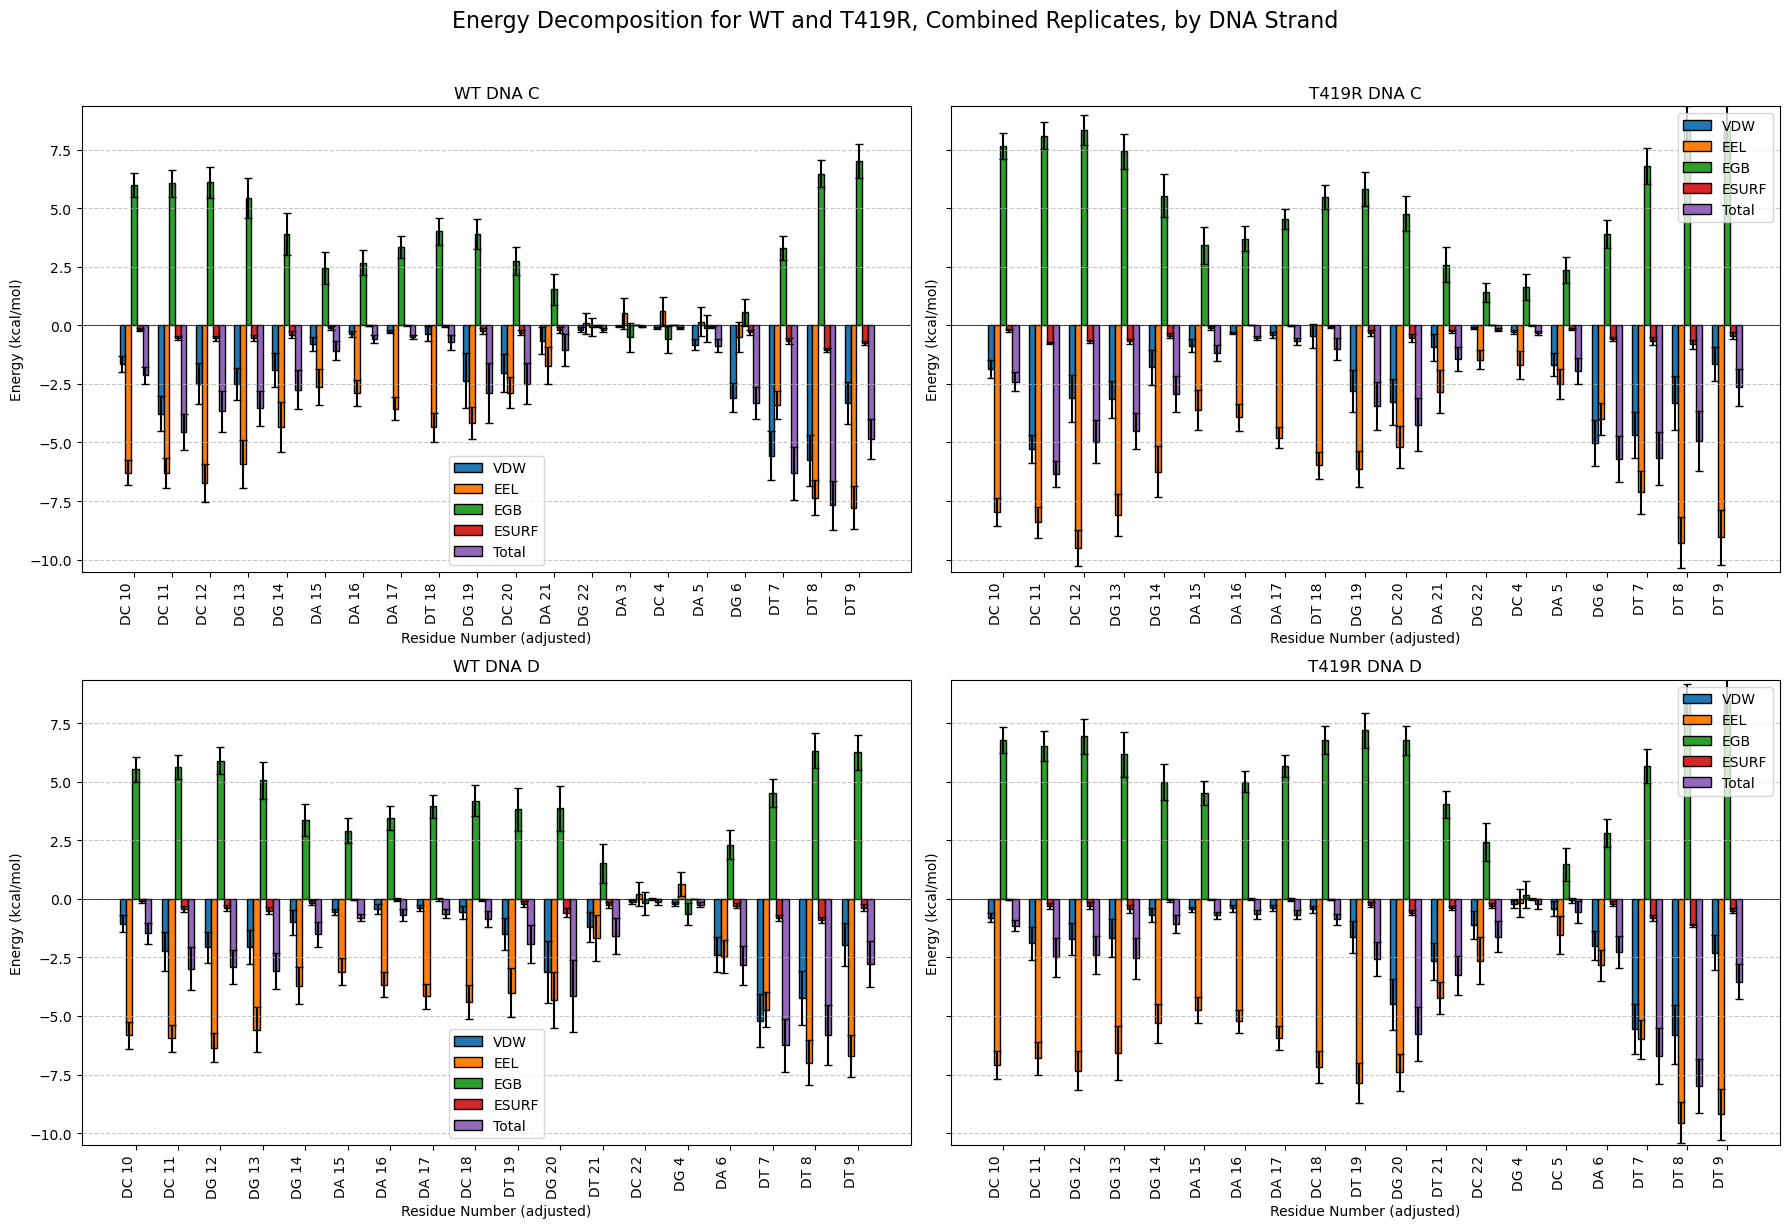

In [48]:
df_wt_dnaC = wt_decomp_combined_df[wt_decomp_combined_df["chain"] == "C"].sort_values(by=["resid_adj"], ascending=True)
df_T419R_dnaC= T419R_decomp_combined_df[T419R_decomp_combined_df["chain"] == "C"].sort_values(by=["resid_adj"], ascending=True)

df_wt_dnaD = wt_decomp_combined_df[wt_decomp_combined_df["chain"] == "D"].sort_values(by=["resid_adj"], ascending=True)
df_T419R_dnaD = T419R_decomp_combined_df[T419R_decomp_combined_df["chain"] == "D"].sort_values(by=["resid_adj"], ascending=True)

energy_terms = [
    'van der Waals_mean', 'Electrostatic_mean', 'Polar Solvation_mean',
    'Non-Polar Solv._mean', 'TOTAL_mean'
]
std_terms = [
    'van der Waals_std', 'Electrostatic_std', 'Polar Solvation_std',
    'Non-Polar Solv._std', 'TOTAL_std'
]

# Find global min and max across all energy terms
all_data = []
for df in [df_wt_dnaC, df_T419R_dnaC, df_wt_dnaD, df_T419R_dnaD]:
    for term in energy_terms:
        all_data.append(df[term].values)
global_min = min([np.nanmin(data) for data in all_data]) * 1.1  
global_max = max([np.nanmax(data) for data in all_data]) * 1.1  

fig, axes = plt.subplots(2, 2, figsize=(18, 12), sharey=True)
ax1, ax2, ax3, ax4 = axes.flatten()

plots = [
    (df_wt_dnaC, ax1, 'WT DNA C'),
    (df_T419R_dnaC, ax2, 'T419R DNA C'),
    (df_wt_dnaD, ax3, 'WT DNA D'),
    (df_T419R_dnaD, ax4, 'T419R DNA D'),
]

# Plotting parameters
n_terms = len(energy_terms)  
bar_width = 0.15 
labels = ['VDW', 'EEL', 'EGB', 'ESURF', 'Total'] 

for df, ax, title in plots:
    filtered_df = df.copy()
    filtered_df['resid_adj'] = pd.to_numeric(filtered_df['resid_adj'])
    
    # Get residue positions and labels
    residues = filtered_df['resid_adj'].values
    res_labels = [f"{resnm} {resid}" for resnm, resid in zip(filtered_df['resnm'], filtered_df['resid_adj'])]
    n_residues = len(residues)
    
    # Set x positions for bars
    x = np.arange(n_residues)  # Base positions for residues
    for i, (term, std, label) in enumerate(zip(energy_terms, std_terms, labels)):
        x_pos = x + i * bar_width - (n_terms - 1) * bar_width / 2
        ax.bar(
            x_pos,
            filtered_df[term],
            yerr=filtered_df[std],
            width=bar_width,
            edgecolor='black',
            capsize=3,
            label=label
        )
    
    # Customize axes
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.set_xlabel('Residue Number (adjusted)')
    ax.set_xticks(x)
    ax.set_xticklabels(res_labels, rotation=90, ha='right')
    ax.legend(loc='best')
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)
    ax.set_ylim(global_min, global_max)

plt.suptitle('Energy Decomposition for WT and T419R, Combined Replicates, by DNA Strand', fontsize=16, y=1.02)

plt.tight_layout()
plt.show()

#### Interpretation - Energy metrics outliers

Residue 419 has outlier values in terms of the difference in the four energy metrics (VDW, EEL, EGB and ESURF) between WT and T419R. 

Values are smaller (contributing to lower binding free energy and higher binding affinity) for VDW, EEL and ESURF in T419R than in WT, while EGB is higher. This reflects a reduction in polar solvation, as analyzed in the 419 residue metrics plots. However, this increase is smaller than the sum of VDW, EEL and ESURF, resulting in a total binding energy that is lower for T419R than WT. 

Although the absolute differences in metrics are smaller for the DNA, it is worth noting that in this compound the higher absolute values for EEL and EGB correspond to residues 6 and 7 in chain C and 19 and 20 (only for EEL) in chain D. These DNA residues were found to form hydrogen bonds with residue 419 in T419R, according to the analysis performed with both MD Analysis and GROMACS. In fact, of these four DNA residues, the only one found to form hydrogen bonds with 419 in both WT and T419R was residue 20, which could be related to it being a less pronounced outlier in the energy metrics. 

Chain C (DNA) residue 8 has higher VDW and ESURF values in T419R, as does chain B (monomer B) residue 418. Chain C (DNA) residue 9 also has higher ESURF. It is worth noting that in all three cases the absolute difference in value between WT and T419R is about 1/3 of the difference of the outliers with lower values in T419R. In any case, these differences in residues 8, 9 and 418 might point at a displacement of the binding towards residue 419 in the mutant, as seen in contact analysis.